In [ ]:
# --- path bootstrap (notebooks were moved to /notebooks on 11 Sep 2026) ---
# The notebook still runs with its ORIGINAL working directory, so every
# relative path and local import further down is unchanged.
import os, sys
from pathlib import Path

_p = Path.cwd().resolve()
while not (_p / "pyproject.toml").exists() and _p != _p.parent:
    _p = _p.parent
REPO_ROOT = _p
os.chdir(REPO_ROOT / "QP_simulator")
sys.path.insert(0, str(Path.cwd()))
print("repo root  :", REPO_ROOT)
print("working dir:", Path.cwd())

# QP Trace Simulation Tutorial

This notebook walks through three things:

1. **Generating clean (noise-free) QP traces** with `QPSimulator` &mdash; the minimal standalone simulator that mirrors the QP/phonon path of `TraceSimulator` exactly.
2. **Using the `NoiseGenerator`** that ships with the project to draw colored Gaussian noise.
3. **Putting them together** &mdash; adding noise on top of a clean QP trace.

Prerequisites: `numpy`, `scipy`, `matplotlib`. The notebook expects to be run from the package root (`TraceSimulator/`).

In [1]:
import sys, os
import numpy as np
import matplotlib.pyplot as plt

# allow `from QPSimulator import QPSimulator` and `from NoiseGenerator import NoiseGenerator`
sys.path.insert(0, os.getcwd())

from QPSimulator import QPSimulator
# Import NoiseGenerator without triggering the full package __init__ (which pulls h5py etc.)
from noise_module.NoiseGenerator import NoiseGenerator

rng = np.random.default_rng(0)

## 1. Clean QP traces with `QPSimulator`

The simulator builds a single-QP calorimetric response template &mdash; an exponential rise (τ_rise) followed by an exponential decay (τ_decay), peaking at `trigger_time` &mdash; and sums one copy per supplied arrival time.

Defaults match `TraceSimulator`: `f_s = 2.5×10⁵ Hz`, `trace_samples = 16384`, `τ_rise = 50 µs`, `τ_decay = 3 ms`, `trigger_time = 10% of the trace`.

Per-QP ADC amplitude:

$$A_\text{QP} = \text{gain}_\text{QE}\;\cdot\;E_\text{ADC}\;\cdot\;10^{-3}\;\cdot\;\text{meV}_\text{per QP}$$

(the $10^{-3}$ converts the $\sim$1 meV per phonon to eV).

In [2]:
sim = QPSimulator()
print(f"dt              = {sim.dt:g} ns")
print(f"trace duration  = {sim.trace_duration*1e-6:.2f} ms ({sim.trace_samples} samples)")
print(f"trigger_time    = {sim.trigger_time*1e-6:.2f} ms")
print(f"τ_rise / τ_decay = {sim.tau_rise*1e-3:g} µs / {sim.tau_decay*1e-6:g} ms")
print(f"per-QP amplitude= {sim.qp_amplitude:.4g} ADC counts")

t_ms = np.arange(sim.trace_samples) * sim.dt * 1e-6   # time axis in ms

dt              = 4000 ns
trace duration  = 65.54 ms (16384 samples)
trigger_time    = 6.55 ms
τ_rise / τ_decay = 50 µs / 3 ms
per-QP amplitude= 0.03 ADC counts


### 1.1 Single QP arriving at t = 0

A QP arriving at `t = 0` produces a peak at `trigger_time`. The peak height equals `qp_amplitude` (modulo discretization).

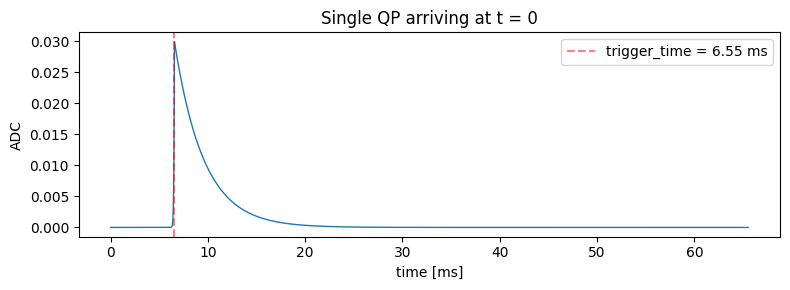

In [3]:
trace = sim.generate([0.0])

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(t_ms, trace, lw=1)
ax.axvline(sim.trigger_time*1e-6, color='r', ls='--', alpha=0.5, label=f'trigger_time = {sim.trigger_time*1e-6:.2f} ms')
ax.set_xlabel("time [ms]"); ax.set_ylabel("ADC")
ax.set_title("Single QP arriving at t = 0"); ax.legend()
fig.tight_layout()

### 1.2 Many QPs sampled from an arrival-time distribution

Real events have many QPs arriving at slightly different times because of ballistic propagation (≈1505–200 m/s in superfluid He-4). Whatever distribution you have for the arrival times — from a detector simulation, an analytic model, or a hand-picked function — just hand it to `generate(arrival_times)`.

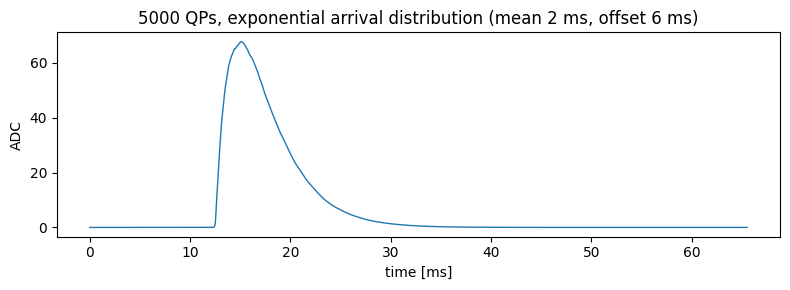

In [4]:
N_QP = 5_000
t_arr = rng.exponential(scale=2e6, size=N_QP) + 6e6   # ns; 2 ms tail starting at 6 ms
trace = sim.generate(t_arr)

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(t_ms, trace, lw=1)
ax.set_xlabel("time [ms]"); ax.set_ylabel("ADC")
ax.set_title(f"{N_QP} QPs, exponential arrival distribution (mean 2 ms, offset 6 ms)")
fig.tight_layout()

### 1.3 Different arrival-time scenarios produce different pulse shapes

This is the "shift-manifold" sandbox &mdash; same QP count, varying arrival-time distribution. Notice both the peak position *and* the pulse shape change.

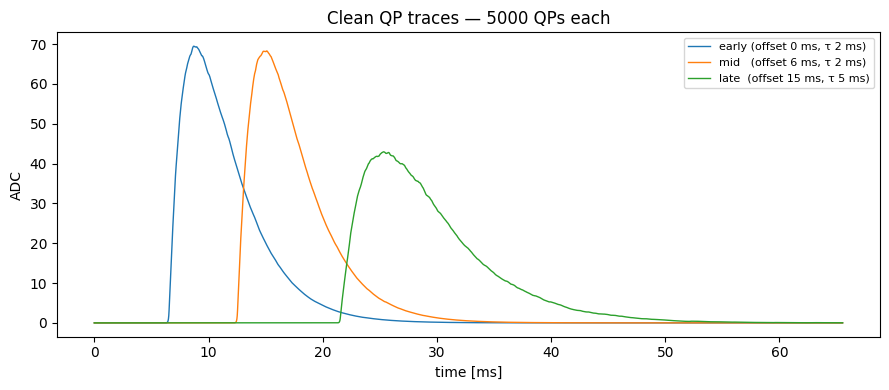

In [5]:
scenarios = {
    "early (offset 0 ms, τ 2 ms)":   rng.exponential(2e6, N_QP) + 0.0,
    "mid   (offset 6 ms, τ 2 ms)":   rng.exponential(2e6, N_QP) + 6e6,
    "late  (offset 15 ms, τ 5 ms)":  rng.exponential(5e6, N_QP) + 15e6,
}

fig, ax = plt.subplots(figsize=(9, 4))
for label, t in scenarios.items():
    ax.plot(t_ms, sim.generate(t), lw=1.0, label=label)
ax.set_xlabel("time [ms]"); ax.set_ylabel("ADC")
ax.set_title(f"Clean QP traces — {N_QP} QPs each"); ax.legend(fontsize=8)
fig.tight_layout()

## 2. The `NoiseGenerator`

`NoiseGenerator` produces a 1D array of colored Gaussian-like noise of length `N`. The constructor needs three keys in its config dict:

| key | meaning |
|---|---|
| `noise_type` | one of `'white' / 'pink' / 'blue' / 'violet' / 'brownian'`, **or** a path to a custom `.npy` PSD file |
| `noise_power` | the time-domain *variance*. So `std = sqrt(noise_power)` |
| `sampling_frequency` | Hz |

Spectral slopes (verified empirically): white = 0, pink = −1, blue = +1, violet = +2, brownian = −2.

In [6]:
cfg = dict(noise_type='pink', noise_power=25.0, sampling_frequency=2.5e5)
ng = NoiseGenerator(cfg)
noise = ng.generate_noise(sim.trace_samples)

print(f"noise_power    = {cfg['noise_power']}")
print(f"empirical std  = {noise.std():.3f}   (≈ sqrt(noise_power) = {np.sqrt(cfg['noise_power']):.3f})")
print(f"empirical mean = {noise.mean():+.4f}")

noise_power    = 25.0
empirical std  = 5.158   (≈ sqrt(noise_power) = 5.000)
empirical mean = -0.0000


### 2.1 Visualizing the five colors

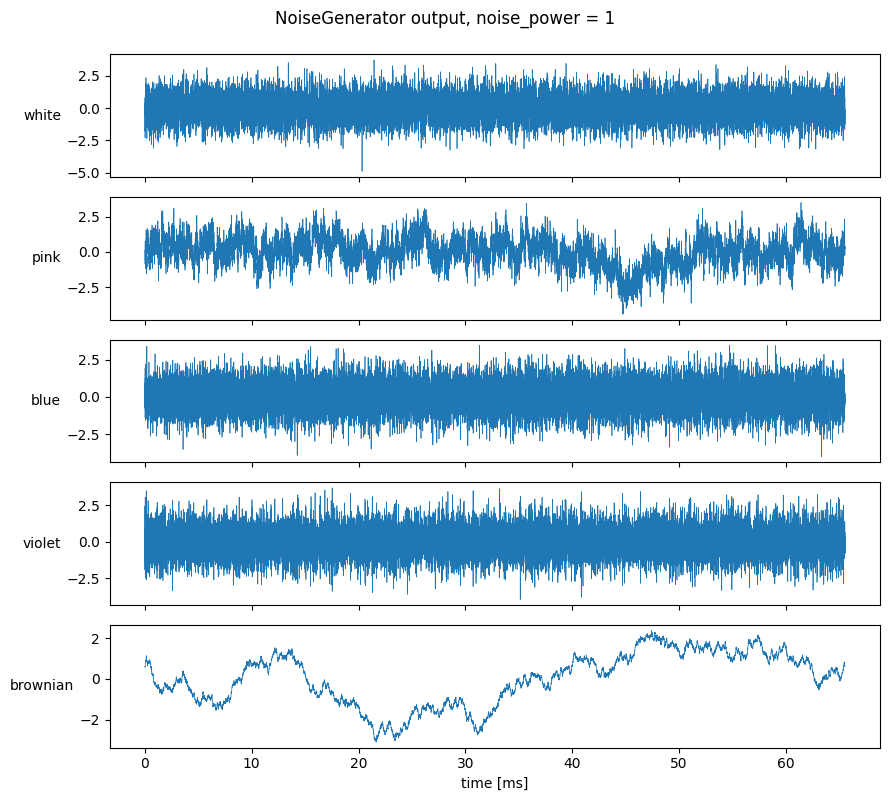

In [7]:
colors = ['white', 'pink', 'blue', 'violet', 'brownian']
fig, axes = plt.subplots(len(colors), 1, figsize=(9, 8), sharex=True)
for ax, c in zip(axes, colors):
    ng = NoiseGenerator(dict(noise_type=c, noise_power=1.0, sampling_frequency=2.5e5))
    n = ng.generate_noise(sim.trace_samples)
    ax.plot(t_ms, n, lw=0.5)
    ax.set_ylabel(c, rotation=0, ha='right', va='center')
axes[-1].set_xlabel("time [ms]")
fig.suptitle("NoiseGenerator output, noise_power = 1", y=0.995)
fig.tight_layout()

### 2.2 Verifying the PSD slopes

Average the periodogram over many traces and fit `log PSD` vs `log f`. Slopes should be (white, pink, blue, violet, brownian) = (0, −1, +1, +2, −2).

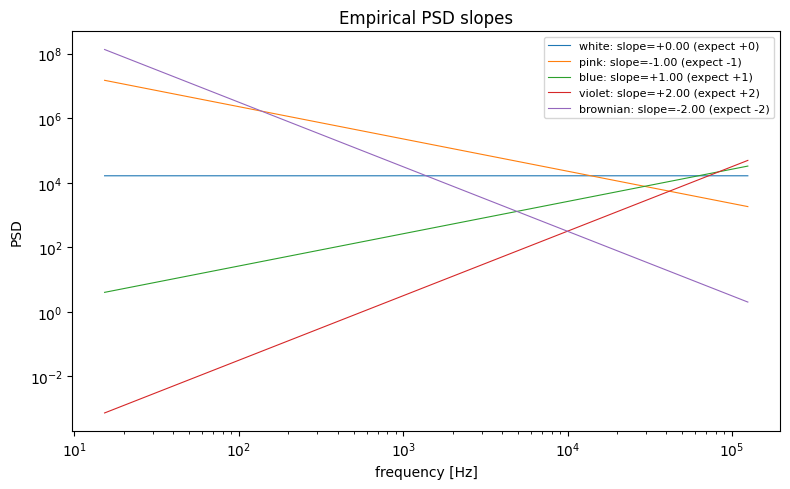

In [8]:
fs = sim.frequency
N  = sim.trace_samples
freq = np.fft.rfftfreq(N, d=1/fs)
mid = (freq > 5) & (freq < 5e4)

fig, ax = plt.subplots(figsize=(8, 5))
for c, expected in [('white', 0), ('pink', -1), ('blue', +1), ('violet', +2), ('brownian', -2)]:
    ng = NoiseGenerator(dict(noise_type=c, noise_power=1.0, sampling_frequency=fs))
    samples = np.stack([ng.generate_noise(N) for _ in range(50)])
    psd = (np.abs(np.fft.rfft(samples, axis=1))**2).mean(axis=0)
    slope, _ = np.polyfit(np.log(freq[mid]), np.log(psd[mid]), 1)
    ax.loglog(freq[1:], psd[1:], lw=0.8, label=f"{c}: slope={slope:+.2f} (expect {expected:+d})")
ax.set_xlabel("frequency [Hz]"); ax.set_ylabel("PSD"); ax.legend(fontsize=8); ax.set_title("Empirical PSD slopes")
fig.tight_layout()

## 3. Putting it together: noisy QP traces

Generate a clean QP trace, draw a noise realization with the same length, sum them. Quantize to integer ADC counts if you want to match the digitizer.

In [9]:
# ---- 1. clean QP trace -------------------------------------------------
N_QP  = 5_000
t_arr = rng.exponential(scale=2e6, size=N_QP) + 6e6     # ns
clean = sim.generate(t_arr)

# ---- 2. noise realization ---------------------------------------------
ng    = NoiseGenerator(dict(noise_type='pink', noise_power=10.0, sampling_frequency=sim.frequency))
noise = ng.generate_noise(sim.trace_samples)

# ---- 3. combine --------------------------------------------------------
noisy = clean + noise
noisy_int = noisy.astype(int)   # if you want integer ADC, like TraceSimulator

# diagnostics
snr = clean.max() / noise.std()
print(f"clean peak  : {clean.max():7.2f} ADC")
print(f"noise std   : {noise.std():7.2f} ADC")
print(f"peak / std  : {snr:7.2f}   (rough single-sample SNR)")

clean peak  :   67.77 ADC
noise std   :    3.26 ADC
peak / std  :   20.78   (rough single-sample SNR)


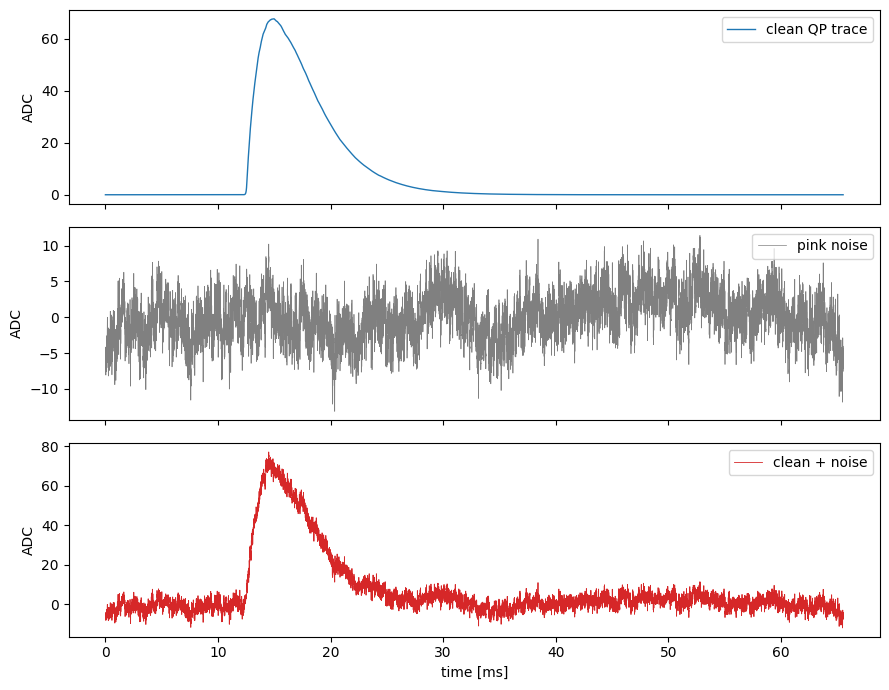

In [10]:
fig, axes = plt.subplots(3, 1, figsize=(9, 7), sharex=True)
axes[0].plot(t_ms, clean, lw=1.0, color='C0', label='clean QP trace')
axes[1].plot(t_ms, noise, lw=0.5, color='gray', label='pink noise')
axes[2].plot(t_ms, noisy, lw=0.6, color='C3', label='clean + noise')
for ax in axes:
    ax.legend(loc='upper right'); ax.set_ylabel('ADC')
axes[-1].set_xlabel('time [ms]')
fig.tight_layout()

### 3.1 Sweeping noise level vs SNR

Same clean trace, varying `noise_power`.

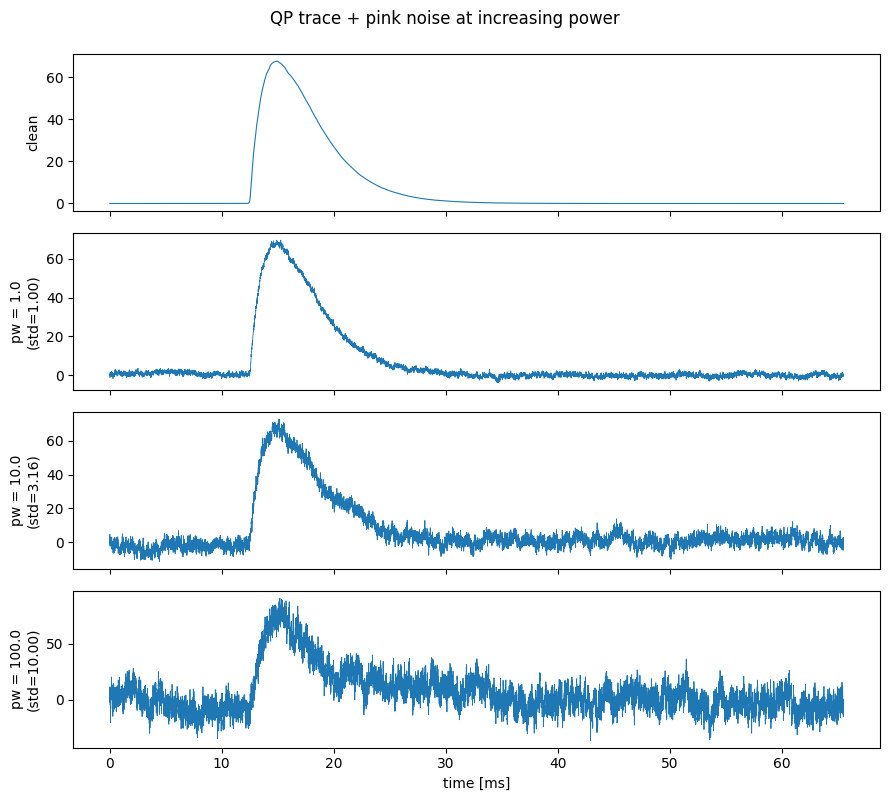

In [11]:
fig, axes = plt.subplots(4, 1, figsize=(9, 8), sharex=True)
for ax, pw in zip(axes, [0.0, 1.0, 10.0, 100.0]):
    if pw == 0.0:
        ax.plot(t_ms, clean, lw=0.8, color='C0')
        ax.set_ylabel('clean')
    else:
        ng = NoiseGenerator(dict(noise_type='pink', noise_power=pw, sampling_frequency=sim.frequency))
        ax.plot(t_ms, clean + ng.generate_noise(sim.trace_samples), lw=0.6)
        ax.set_ylabel(f'pw = {pw}\n(std={np.sqrt(pw):.2f})')
axes[-1].set_xlabel('time [ms]')
fig.suptitle('QP trace + pink noise at increasing power', y=0.995)
fig.tight_layout()

### 3.2 Generating an ensemble of (clean, noisy) pairs

Convenient pattern for training/evaluation datasets: pair each clean trace with an independent noise draw.

clean_ds shape: (20, 16384)
noisy_ds shape: (20, 16384)


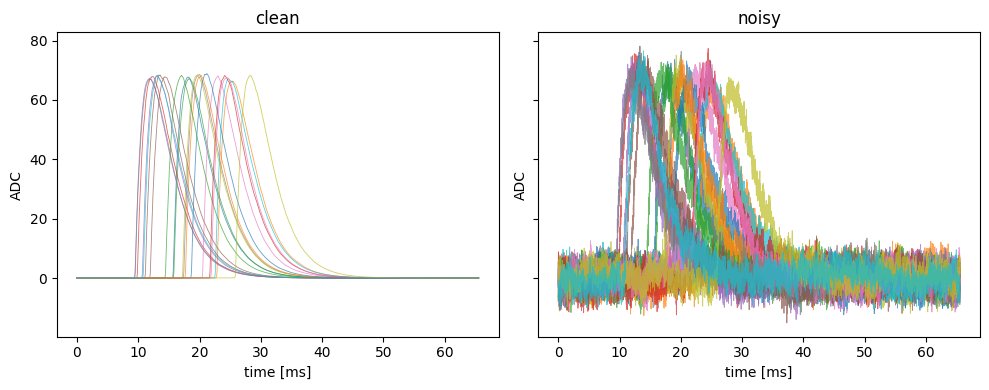

In [12]:
n_events  = 20
ng        = NoiseGenerator(dict(noise_type='pink', noise_power=10.0, sampling_frequency=sim.frequency))

clean_ds  = np.empty((n_events, sim.trace_samples))
noisy_ds  = np.empty((n_events, sim.trace_samples))
offsets   = rng.uniform(2e6, 20e6, n_events)   # different per-event arrival-time offsets (ns)

for k in range(n_events):
    t_arr        = rng.exponential(scale=2e6, size=N_QP) + offsets[k]
    clean_ds[k]  = sim.generate(t_arr)
    noisy_ds[k]  = clean_ds[k] + ng.generate_noise(sim.trace_samples)

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
axes[0].plot(t_ms, clean_ds.T, lw=0.6, alpha=0.7); axes[0].set_title('clean')
axes[1].plot(t_ms, noisy_ds.T, lw=0.6, alpha=0.7); axes[1].set_title('noisy')
for ax in axes:
    ax.set_xlabel('time [ms]'); ax.set_ylabel('ADC')
fig.tight_layout()
print(f"clean_ds shape: {clean_ds.shape}")
print(f"noisy_ds shape: {noisy_ds.shape}")

## 4. New API: batch generation, shifted templates, and PSD estimation

This section covers four additions to `QPSimulator` that support the
paper's experiment suite:

| Method | Purpose |
|---|---|
| `generate(…, return_amplitude=True)` | Ground-truth amplitude alongside a single trace |
| `generate_family(…)` | Batch of N traces with per-event parameter variation and ground-truth dict |
| `get_template_at_shift(t0_shift_ns)` | Shifted single-QP template for time-shift optimal filtering |
| `estimate_psd(noise_traces, fs)` | One-sided PSD from noise-only traces (static method) |


### 4.1 `return_amplitude=True` — ground-truth amplitude for a single event

When you need to compare an estimator's output against the true signal
amplitude without calling `generate_family`, pass `return_amplitude=True`.
The second return value is `n_inside × qp_amplitude`, where `n_inside` is
the number of arrival times that fell inside `[0, trace_duration)`.

In [13]:
arrivals = rng.exponential(scale=2e6, size=5_000) + sim.trigger_time

# Original behaviour — unchanged
trace_only = sim.generate(arrivals)

# New: get trace AND ground-truth amplitude in one call
trace, amp_true = sim.generate(arrivals, return_amplitude=True)

print(f'trace shape  : {trace.shape}')
print(f'amp_true     : {amp_true:.4f} ADC  ')
print(f'expected ≈   : {5000 * sim.qp_amplitude:.4f} ADC  (5000 × {sim.qp_amplitude:.4f})')
print(f'backward-compat check: arrays identical = {np.allclose(trace, trace_only)}')

trace shape  : (16384,)
amp_true     : 150.0000 ADC  
expected ≈   : 150.0000 ADC  (5000 × 0.0300)
backward-compat check: arrays identical = True


### 4.2 `generate_family()` — batch generation with per-event variation

`generate_family()` returns:

- **`traces`** — `np.ndarray` of shape `(n_events, trace_samples)`, clean (no noise)
- **`params`** — dict with keys `tau_decay`, `t0_shift`, `n_QP`, `amplitude_ADC`

Per-event `tau_decay`, arrival-time jitter, and QP count are each drawn
independently from the specified ranges. Pass `(x, x)` for a fixed value.

The design follows the existing QPSimulator convention: **noise is not added here**.
Apply it externally using `NoiseGenerator` or `MultiChannelNoiseGenerator`
so the same clean family can be reused across different noise experiments.

In [14]:
traces, params = sim.generate_family(
    n_events       = 200,
    tau_decay_range = (2e6, 4e6),     # ns: vary decay time ±33%
    t0_jitter_range = (-5e4, 5e4),    # ns: ±50 µs trigger jitter
    n_QP_range      = (2000, 8000),   # vary signal energy
    rng             = rng,
)

print(f'traces shape     : {traces.shape}')
print(f'tau_decay range  : [{params["tau_decay"].min()*1e-6:.2f}, {params["tau_decay"].max()*1e-6:.2f}] ms')
print(f't0_shift range   : [{params["t0_shift"].min()*1e-3:.0f}, {params["t0_shift"].max()*1e-3:.0f}] µs')
print(f'n_QP range       : [{params["n_QP"].min()}, {params["n_QP"].max()}]')
print(f'amplitude range  : [{params["amplitude_ADC"].min():.2f}, {params["amplitude_ADC"].max():.2f}] ADC')

traces shape     : (200, 16384)
tau_decay range  : [2.00, 3.99] ms
t0_shift range   : [-49, 49] µs
n_QP range       : [2003, 7995]
amplitude range  : [60.09, 239.85] ADC


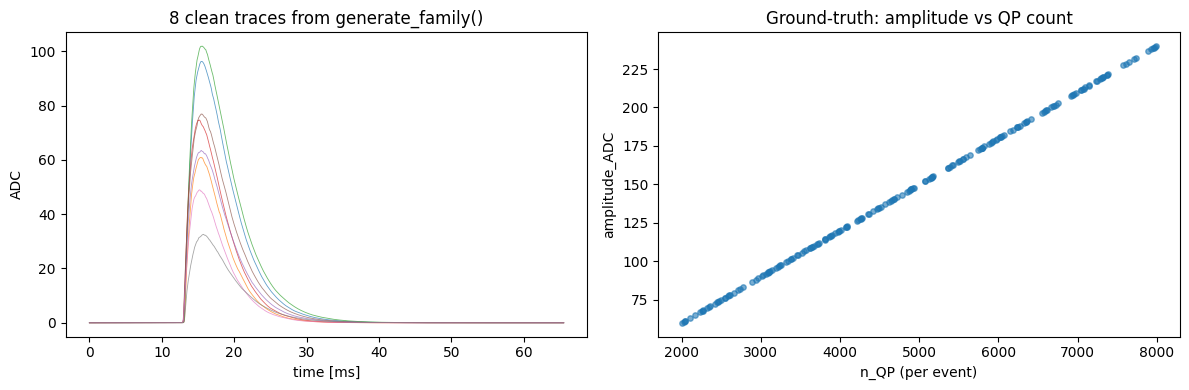

In [15]:
# Visualize: first 8 clean traces and amplitude vs n_QP scatter
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for i in range(8):
    axes[0].plot(t_ms, traces[i], lw=0.6, alpha=0.7)
axes[0].set_xlabel('time [ms]'); axes[0].set_ylabel('ADC')
axes[0].set_title('8 clean traces from generate_family()')

axes[1].scatter(params['n_QP'], params['amplitude_ADC'], s=15, alpha=0.6)
axes[1].set_xlabel('n_QP (per event)'); axes[1].set_ylabel('amplitude_ADC')
axes[1].set_title('Ground-truth: amplitude vs QP count')

fig.tight_layout()

#### 4.2.1 The standard experiment pipeline

```
generate_family()   →   add noise externally   →   estimate_psd()   →   run estimator   →   compare to params
```

The cell below demonstrates this end-to-end for a simple amplitude-recovery check.

In [16]:
# 1. Clean family
traces_clean, params = sim.generate_family(
    n_events=500, n_QP_range=(4000, 6000), rng=rng
)

# 2. Add pink noise to every event
ng = NoiseGenerator(dict(noise_type='pink', noise_power=5.0,
                         sampling_frequency=sim.frequency))
traces_noisy = traces_clean + np.stack(
    [ng.generate_noise(sim.trace_samples) for _ in range(500)]
)

# 3. Estimate PSD from 200 dedicated noise-only traces
noise_only = np.stack([ng.generate_noise(sim.trace_samples) for _ in range(200)])
freqs, Jk = QPSimulator.estimate_psd(noise_only, sim.frequency)

# 4. Toy amplitude estimator: project each noisy trace onto the template
#    using the noise-weighted inner product  Â = (s†Σ⁻¹x) / (s†Σ⁻¹s)
s = sim.template[:sim.trace_samples]          # nominal template (not scaled)
S = np.fft.rfft(s)
Jk_safe = np.maximum(Jk, 1e-30)               # ridge floor
of_kernel = S.conj() / Jk_safe

A_hat = np.array([
    np.real(np.dot(of_kernel, np.fft.rfft(x))) /
    np.real(np.dot(of_kernel, S))
    for x in traces_noisy
])

A_true = params['amplitude_ADC']
residuals = A_hat - A_true
print(f'bias  : {residuals.mean():+.4f} ADC')
print(f'std   : {residuals.std():.4f} ADC')
print(f'|bias|/std: {abs(residuals.mean())/residuals.std():.3f}  (should be ≪ 1 for unbiased estimator)')

bias  : -0.0000 ADC
std   : 0.0000 ADC
|bias|/std: 4.642  (should be ≪ 1 for unbiased estimator)


### 4.3 `get_template_at_shift()` — shifted templates for time-shift optimal filtering

For the time-shift optimal-filtering experiment (E8 in the paper checklist),
you need to build a filter kernel at each candidate time offset.
`get_template_at_shift(t0_shift_ns)` returns the single-QP template
shifted by `t0_shift_ns` nanoseconds relative to `self.trigger_time`,
truncated to `trace_samples`.

The returned array is the **unnormalised template** (peak ≈ 1), not scaled
by `qp_amplitude` — multiply by `qp_amplitude` if you need ADC units.

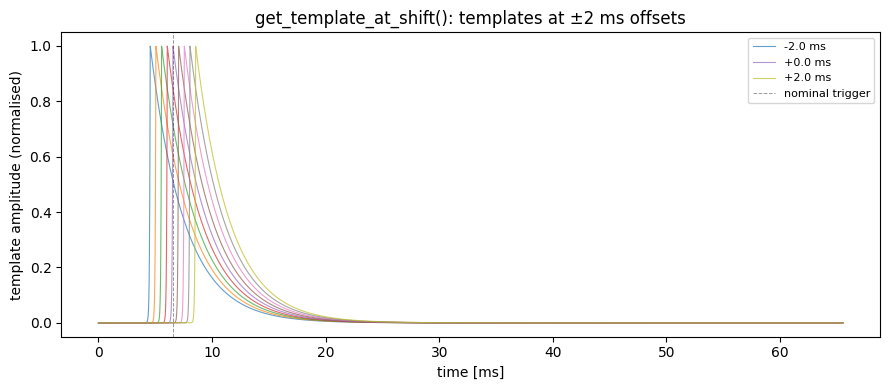

In [17]:
shifts_ms = np.linspace(-2, 2, 9)   # ±2 ms in steps of 0.5 ms

fig, ax = plt.subplots(figsize=(9, 4))
for ds in shifts_ms:
    tmpl = sim.get_template_at_shift(ds * 1e6)   # convert ms → ns
    ax.plot(t_ms, tmpl, lw=0.8, alpha=0.7, label=f'{ds:+.1f} ms' if abs(ds) in (0, 2) else '')

ax.axvline(sim.trigger_time * 1e-6, color='k', ls='--', lw=0.7, alpha=0.4, label='nominal trigger')
ax.set_xlabel('time [ms]'); ax.set_ylabel('template amplitude (normalised)')
ax.set_title('get_template_at_shift(): templates at ±2 ms offsets')
ax.legend(fontsize=8)
fig.tight_layout()

In [18]:
# Verify: peak shifts by exactly the requested number of samples
for ds_ms in [-1.0, 0.0, 0.5, 1.0]:
    tmpl = sim.get_template_at_shift(ds_ms * 1e6)
    peak_sample = np.argmax(tmpl)
    expected    = int(round((sim.trigger_time + ds_ms * 1e6) / sim.dt))
    print(f'shift {ds_ms:+.1f} ms → peak at sample {peak_sample:5d}  (expected {expected:5d})')

shift -1.0 ms → peak at sample  1389  (expected  1388)
shift +0.0 ms → peak at sample  1639  (expected  1638)
shift +0.5 ms → peak at sample  1764  (expected  1763)
shift +1.0 ms → peak at sample  1889  (expected  1888)


### 4.4 `estimate_psd()` — one-sided PSD from noise-only traces

`QPSimulator.estimate_psd(noise_traces, sampling_frequency)` is a static
method that computes the averaged periodogram across a `(N_traces, trace_samples)`
array of noise-only traces and returns the one-sided PSD `J_k` (ADC²/Hz).

**Normalisation:** `J_k = mean(|FFT(x)|²) × 2 / (N × f_s)`

so that `sum(J_k) × (f_s / N) ≈ noise_power` — the same convention used
internally by `NoiseGenerator`.

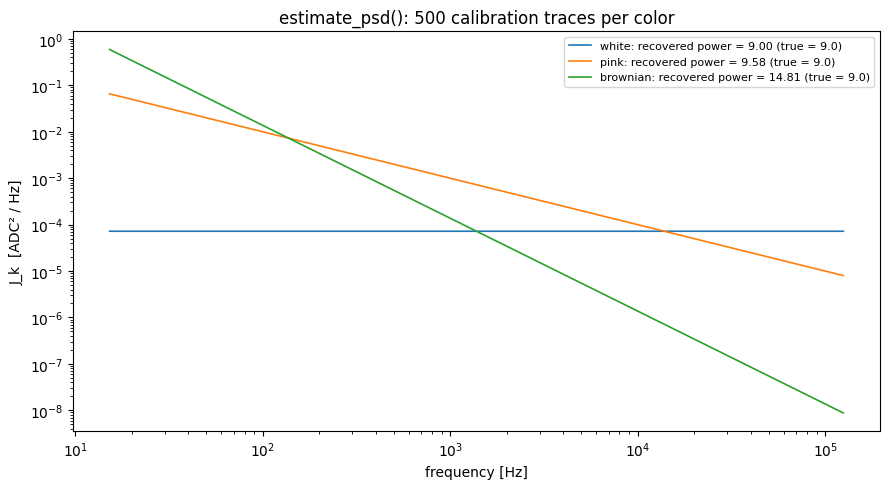

In [19]:
# Generate 500 noise-only traces at known power for each color
known_power = 9.0   # ADC²
N_cal = 500

fig, ax = plt.subplots(figsize=(9, 5))
for color in ['white', 'pink', 'brownian']:
    ng_cal = NoiseGenerator(dict(noise_type=color, noise_power=known_power,
                                  sampling_frequency=sim.frequency))
    cal_traces = np.stack([ng_cal.generate_noise(sim.trace_samples) for _ in range(N_cal)])
    freqs_est, Jk_est = QPSimulator.estimate_psd(cal_traces, sim.frequency)

    # Recovered power = integral of one-sided PSD over positive frequencies
    recovered = Jk_est.sum() * (sim.frequency / sim.trace_samples)
    ax.loglog(freqs_est[1:], Jk_est[1:], lw=1.2,
              label=f'{color}: recovered power = {recovered:.2f} (true = {known_power})')

ax.set_xlabel('frequency [Hz]'); ax.set_ylabel('J_k  [ADC² / Hz]')
ax.set_title(f'estimate_psd(): {N_cal} calibration traces per color')
ax.legend(fontsize=8)
fig.tight_layout()

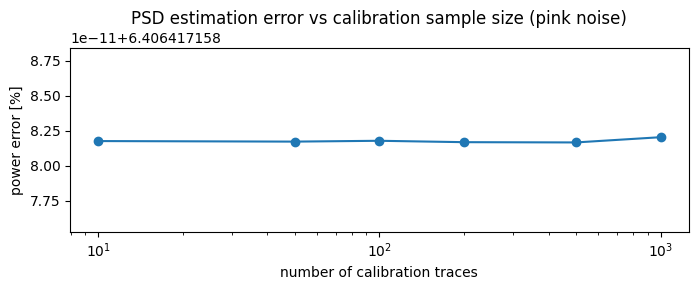

In [20]:
# Quantify estimation error vs number of calibration traces
ng_pink = NoiseGenerator(dict(noise_type='pink', noise_power=known_power,
                               sampling_frequency=sim.frequency))
n_cal_sweep = [10, 50, 100, 200, 500, 1000]
errors = []
for n_cal in n_cal_sweep:
    cal = np.stack([ng_pink.generate_noise(sim.trace_samples) for _ in range(n_cal)])
    _, Jk_est = QPSimulator.estimate_psd(cal, sim.frequency)
    recovered = Jk_est.sum() * (sim.frequency / sim.trace_samples)
    errors.append(abs(recovered - known_power) / known_power * 100)

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(n_cal_sweep, errors, 'o-')
ax.set_xlabel('number of calibration traces'); ax.set_ylabel('power error [%]')
ax.set_title('PSD estimation error vs calibration sample size (pink noise)')
ax.set_xscale('log')
fig.tight_layout()

## Recap

**Core API**

- **`QPSimulator(...)`** — build once with your digitizer/template parameters.
- **`sim.generate(arrival_times_ns)`** — clean trace, shape `(trace_samples,)`.
- **`sim.generate(arrival_times_ns, return_amplitude=True)`** — `(trace, amp_true)`, where `amp_true = n_inside × qp_amplitude`.

**Batch / experiment API** *(new)*

- **`sim.generate_family(n_events, tau_decay_range, t0_jitter_range, n_QP_range, rng)`**
  — `(traces, params)` where `traces` is `(N, trace_samples)` and `params` is a dict with `tau_decay`, `t0_shift`, `n_QP`, `amplitude_ADC` — all per-event ground truth. No noise added; apply externally.
- **`sim.get_template_at_shift(t0_shift_ns)`** — single-QP template shifted by `t0_shift_ns` ns from `trigger_time`. Use to build time-shift OF filter banks.
- **`QPSimulator.estimate_psd(noise_traces, fs)`** — static method; averaged periodogram from `(N_traces, trace_samples)` noise-only array. Returns `(freqs, J_k)`.

**Standard experiment pipeline**

```python
# 1. Clean family with ground truth
traces_clean, params = sim.generate_family(n_events=500, n_QP_range=(3000, 7000), rng=rng)
# 2. Add noise externally
traces_noisy = traces_clean + np.stack([ng.generate_noise(sim.trace_samples) for _ in range(500)])
# 3. PSD from dedicated noise-only calibration traces
freqs, Jk = QPSimulator.estimate_psd(noise_cal_traces, sim.frequency)
# 4. Run estimator → compare output to params['amplitude_ADC']
```

**Noise module** (unchanged)

- **`NoiseGenerator({'noise_type': 'pink', 'noise_power': σ², 'sampling_frequency': f_s})`** — `ng.generate_noise(N)` returns an independent realization each call.
- **`MultiChannelNoiseGenerator`** — correlated multi-channel noise.
- **`ArtifactInjector`** and **`TemporalNoiseWrapper`** — glitches, drift, piecewise-stationary effects.

The clean-trace path is bit-equivalent (to one float64 ulp) with the QP/phonon path of the full `TraceSimulator`.

## 5. Training an NFPA on the HeST arm — and reading its latent space

Sections 1&ndash;4 built the pieces: an arrival-time distribution goes in, a
clean CPD trace comes out, `noise_module` colours the noise. This section
closes the loop. **HeST** goes in front of `QPSimulator`, so the arrival
times come from real quasiparticle transport in superfluid $^4$He; the
24-CPD HeRALD_v1 array gets a $\Sigma_c\otimes\Sigma_t$ noise model; and then
we **train an NFPA** &mdash; the noise-factored projection autoencoder, a
covariance-weighted Tucker-2 projection written as a tied
encoder&ndash;decoder &mdash; on the result.

The question is not how small the reconstruction error gets. It is whether
the latent coordinates **mean** anything physical, and whether that meaning
can be *checked* rather than asserted. The simulation chain supplies the
ground truth to check it against, one factor at a time.

| stage | what it produces |
|---|---|
| HeST `GetQuanta` + `GetEvaporationSignal` | which CPD each quasiparticle hit, and when |
| `QPSimulator.generate` | one clean CPD trace per channel, $(C, d)$ |
| `MultiChannelNoiseGenerator` | $\Sigma = \Sigma_c \otimes \Sigma_t$ noise |
| `SeparableWhitener` | $\tilde Z = \Sigma_c^{-1/2}X\,\Sigma_t^{-1/2}$ |
| NFPA | $\Gamma = U_c^{\mathsf T}\tilde Z U_t \in \mathbb R^{k_c\times k_t}$ |

Everything below is numpy + scipy plus the two simulators.

In [1]:
import json
import os
import sys
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

_here = Path.cwd()
REPO = _here.parent if _here.name == "QP_simulator" else _here
for _p in (REPO / "QP_simulator", REPO / "src" / "NFPA", REPO / "noise_module"):
    sys.path.insert(0, str(_p))

import hest_qp_dataset as ds          # HeST -> QPSimulator -> noise_module
import nfpa_separable as nf           # the NFPA architecture and its fitting
import physics_basis as pb            # physical bases + factorisation check
from QPSimulator import QPSimulator

plt.rcParams.update({"figure.dpi": 110, "font.size": 8.5, "axes.titlesize": 9,
                     "axes.labelsize": 8.5, "legend.fontsize": 7,
                     "axes.grid": True, "grid.alpha": 0.25,
                     "grid.linewidth": 0.5, "figure.facecolor": "white"})
CB = dict(blue="#2c6fbb", orange="#d9772b", green="#3f9e56", red="#c0392b",
          grey="#7f8c8d", purple="#8e5ea2")

# NFPA_QUICK=1 in the environment runs the whole section on tiny samples in a
# couple of minutes -- handy for checking the chain before a full run.
QUICK = bool(int(os.environ.get("NFPA_QUICK", "0")))
N_TRAIN, N_TEST, N_CELL, N_NOISE = (60, 40, 25, 120) if QUICK else (1200, 400, 120, 600)
EPOCHS, RESTARTS = (8, 2) if QUICK else (90, 10)
CALIB_QP = 20_000 if QUICK else 120_000
LIB = Path("lib_quick" if QUICK else "lib_nfpa"); LIB.mkdir(exist_ok=True)

FS, D_RAW = ds.FS, ds.TRACE_SAMPLES
FS_E, D_T = ds.FS_EFF, ds.D_EFF
TAU_RISE, TAU_NOM, TRIG = ds.TAU_RISE, ds.TAU_DECAY_NOM, ds.TRIGGER_TIME
QP_AMP = ds.qp_amplitude()
t_ms = np.arange(D_T) / FS_E * 1e3
F_SIG = 1.0 / (2 * np.pi * TAU_RISE * 1e-9)      # Hz, CPD signal bandwidth

print(f"raw record    : {D_RAW} samples @ {FS/1e3:.0f} kHz = {D_RAW/FS*1e3:.2f} ms")
print(f"after {ds.DECIMATE}x decimation: {D_T} samples @ {FS_E/1e3:.1f} kHz")
print(f"CPD response  : tau_rise {TAU_RISE*1e-3:.0f} us, tau_decay {TAU_NOM*1e-6:.1f} ms")
print(f"signal band   : f_sig = 1/(2 pi tau_rise) = {F_SIG:.0f} Hz "
      f"(Nyquist after decimation {FS_E/2e3:.1f} kHz)")
print(f"noise         : {ds.NOISE_TYPE}, {ds.NOISE_POWER:g} ADC^2 "
      f"(sigma {np.sqrt(ds.NOISE_POWER):.1f} ADC), channel corr {ds.CORR_STRENGTH}")

raw record    : 2048 samples @ 250 kHz = 8.19 ms
after 4x decimation: 512 samples @ 62.5 kHz
CPD response  : tau_rise 50 us, tau_decay 3.0 ms
signal band   : f_sig = 1/(2 pi tau_rise) = 3183 Hz (Nyquist after decimation 31.2 kHz)
noise         : pink, 16 ADC^2 (sigma 4.0 ADC), channel corr 0.35


### 5.1 An event library, then traces

The expensive stage is HeST: about a second per event, 2200 events here. It
is also the only stage that is *physics*. So it runs once and caches, per
event, which CPD every detected quasiparticle hit and when &mdash; about
10 kB per event. Rendering traces from that library is exact and takes
milliseconds, and the CPD decay time $\tau$ and trigger offset $t_0$ are not
HeST quantities at all, so they are drawn at **render** time. That is what
makes the trigger-jitter sweep in §5.8 free.

Each event is an ER deposit at $(x_v,y_v,z_v)$ with energy $E$. Four
quantities vary independently:

| factor | drawn from | where it should appear |
|---|---|---|
| amplitude $A$ (via $E$) | log-U(0.5, 2) keV | the code entry along $s$ |
| vertex $x_v, y_v$ | uniform in $r < 2.5$ cm | the **channel** factor $U_c$ |
| trigger offset $t_0$ | U($\pm 25\ \mu$s) $=\pm0.5\,\tau_{\rm rise}$ | the **time** factor, along $\partial_t s$ |
| CPD decay $\tau$ | U($\pm 40\%$) of 3 ms | the **time** factor, along $\partial_\tau s$ |

Depth $z_v$ varies too (it changes the collected fraction). Five one-factor
cells freeze everything but a single quantity &mdash; the controlled-variable
discipline that makes "which factor moved" identifiable instead of a matter
of interpretation.

One DAQ choice matters for everything that follows. The CPD response is
band-limited at $f_{\rm sig}\approx3$ kHz, so a 250 kHz record spends 97% of
its dimensions on noise-only bins. Decimating by 4 (with the anti-alias
filter a real DAQ applies anyway) keeps all of the signal and takes $d$ from
2048 to 512, which is what moves the subspace estimate out of the regime
where the weak directions sit under the Marchenko&ndash;Pastur edge. §5.3
shows the margins.

In [2]:
t_gen = time.time()
train_lib = ds.build_event_library("reference", N_TRAIN, seed=1, path=LIB / "ref_train.npz")
test_lib = ds.build_event_library("reference", N_TEST, seed=2, path=LIB / "ref_test.npz")
CELL_NAMES = ["energy_only", "x_only", "y_only", "t0_only", "tau_only"]
CELL_LIBS = {nm: ds.build_event_library(nm, N_CELL, seed=11 + i,
                                        path=LIB / f"cell_{nm}.npz")
             for i, nm in enumerate(CELL_NAMES)}
print(f"libraries ready in {time.time()-t_gen:.0f} s")

share_tr, ndet_tr, tmed_tr = ds.library_summary(train_lib)
share_te, ndet_te, tmed_te = ds.library_summary(test_lib)
truth = {k[6:]: train_lib[k] for k in train_lib.files if k.startswith("truth_")}
truth_te = {k[6:]: test_lib[k] for k in test_lib.files if k.startswith("truth_")}
C = int(train_lib["n_channels"])
SENSOR_XY = train_lib["sensor_xy"]

t0_tr, tau_tr = ds.response_params(N_TRAIN, seed=101)
t0_te, tau_te = ds.response_params(N_TEST, seed=102)
truth["t0"], truth["tau"] = t0_tr, tau_tr
truth_te["t0"], truth_te["tau"] = t0_te, tau_te

clean_tr = ds.downsample(ds.render_traces(train_lib, t0=t0_tr, tau=tau_tr))
clean_te = ds.downsample(ds.render_traces(test_lib, t0=t0_te, tau=tau_te))
X_tr = ds.downsample(ds.add_noise(ds.render_traces(train_lib, t0=t0_tr, tau=tau_tr),
                                  seed=10_001))
X_te = ds.downsample(ds.add_noise(ds.render_traces(test_lib, t0=t0_te, tau=tau_te),
                                  seed=10_002))
noise_rec = ds.downsample(ds.noise_only(N_NOISE, C, D_RAW, seed=99))

# realised amplitude: detected QPs, thinning undone, times the per-QP ADC scale
A_tr = ndet_tr / ds.QP_FRACTION * QP_AMP
A_te = ndet_te / ds.QP_FRACTION * QP_AMP

print(f"train {X_tr.shape}, test {X_te.shape}, noise-only {noise_rec.shape}")
print(f"detected QP per event (thinned): median {np.median(ndet_tr):.0f}")
print(f"realised amplitude A: {A_tr.min():.0f} - {A_tr.max():.0f} ADC")
print(f"per-channel peak / sigma: "
      f"{np.median(clean_tr.max(axis=(1,2)))/np.sqrt(ds.NOISE_POWER):.1f}")

libraries ready in 0 s
train (1200, 24, 512), test (400, 24, 512), noise-only (600, 24, 512)
detected QP per event (thinned): median 2250
realised amplitude A: 185 - 1142 ADC
per-channel peak / sigma: 15.9


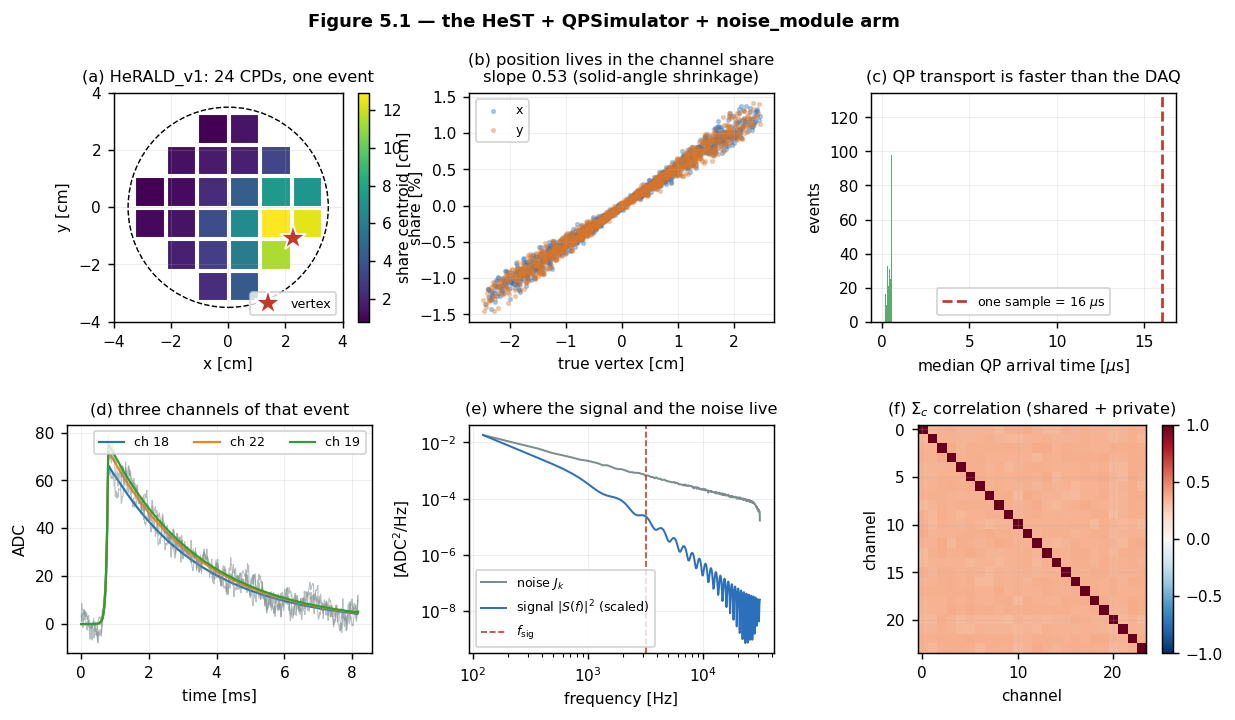

In [3]:
fig = plt.figure(figsize=(11, 5.6))
gs = fig.add_gridspec(2, 3, hspace=0.45, wspace=0.32)

ax = fig.add_subplot(gs[0, 0])
ev = int(np.argmax(np.hypot(truth["x"], truth["y"]) * (A_tr > np.median(A_tr))))
sc = ax.scatter(SENSOR_XY[:, 0], SENSOR_XY[:, 1], c=share_tr[ev] * 100, s=250,
                marker="s", cmap="viridis", edgecolor="w", linewidth=0.6)
ax.plot(truth["x"][ev], truth["y"][ev], "*", color=CB["red"], ms=15,
        markeredgecolor="w", label="vertex")
ax.add_patch(plt.Circle((0, 0), 3.5, fill=False, ls="--", lw=0.8, color="k"))
fig.colorbar(sc, ax=ax, label="share [%]", fraction=0.046)
ax.set(xlabel="x [cm]", ylabel="y [cm]", xlim=(-4, 4), ylim=(-4, 4),
       aspect="equal", title="(a) HeRALD_v1: 24 CPDs, one event")
ax.legend(loc="lower right")

ax = fig.add_subplot(gs[0, 1])
cx, cy = share_tr @ SENSOR_XY[:, 0], share_tr @ SENSOR_XY[:, 1]
ax.scatter(truth["x"], cx, s=4, alpha=0.3, color=CB["blue"], label="x")
ax.scatter(truth["y"], cy, s=4, alpha=0.3, color=CB["orange"], label="y")
sl = np.polyfit(truth["x"], cx, 1)[0]
ax.set(xlabel="true vertex [cm]", ylabel="share centroid [cm]",
       title=f"(b) position lives in the channel share\nslope {sl:.2f} "
             "(solid-angle shrinkage)")
ax.legend()

ax = fig.add_subplot(gs[0, 2])
ax.hist(tmed_tr * 1e-3, bins=40, color=CB["green"], alpha=0.85)
ax.axvline(1e9 / FS_E * 1e-3, color=CB["red"], ls="--",
           label=f"one sample = {1e9/FS_E*1e-3:.0f} $\\mu$s")
ax.set(xlabel=r"median QP arrival time [$\mu$s]", ylabel="events",
       title="(c) QP transport is faster than the DAQ")
ax.legend()

ax = fig.add_subplot(gs[1, 0])
for c in np.argsort(share_tr[ev])[-3:]:
    ax.plot(t_ms, X_tr[ev, c], lw=0.6, alpha=0.55, color=CB["grey"])
    ax.plot(t_ms, clean_tr[ev, c], lw=1.2, label=f"ch {c}")
ax.set(xlabel="time [ms]", ylabel="ADC",
       title="(d) three channels of that event")
ax.legend(ncol=3)

ax = fig.add_subplot(gs[1, 1])
f_ax, Jk = QPSimulator.estimate_psd(noise_rec[:, 0, :], FS_E)
ax.loglog(f_ax[1:], Jk[1:], lw=1.1, color=CB["grey"], label=r"noise $J_k$")
s_ref = ds.downsample(QPSimulator(sampling_frequency=FS, trace_samples=D_RAW,
                                  tau_rise=TAU_RISE,
                                  tau_decay=TAU_NOM).template[:D_RAW])
Sf = np.abs(np.fft.rfft(s_ref)) ** 2
ax.loglog(f_ax[1:], Sf[1:] / Sf[1] * Jk[1], lw=1.1, color=CB["blue"],
          label=r"signal $|S(f)|^2$ (scaled)")
ax.axvline(F_SIG, color=CB["red"], ls="--", lw=0.9, label=r"$f_{\rm sig}$")
ax.set(xlabel="frequency [Hz]", ylabel=r"[ADC$^2$/Hz]",
       title="(e) where the signal and the noise live")
ax.legend()

ax = fig.add_subplot(gs[1, 2])
nn = min(len(noise_rec), 100)
Sc = np.einsum("nct,ndt->cd", noise_rec[:nn], noise_rec[:nn]) / (nn * D_T)
im = ax.imshow(Sc / np.sqrt(np.outer(np.diag(Sc), np.diag(Sc))), cmap="RdBu_r",
               vmin=-1, vmax=1)
fig.colorbar(im, ax=ax, fraction=0.046)
ax.set(xlabel="channel", ylabel="channel",
       title=r"(f) $\Sigma_c$ correlation (shared + private)")
fig.suptitle("Figure 5.1 — the HeST + QPSimulator + noise_module arm",
             y=0.99, fontsize=10, fontweight="bold")
plt.show()

### 5.2 [W] — the separable whitener

The noise is one shared coloured process plus per-channel private noise with
a common PSD, so $\Sigma = \Sigma_c\otimes\Sigma_t$ *exactly* and the
whitener factorises: $\Sigma_c^{-1/2}$ on the channel index, $1/\sqrt{J_k}$
on the frequency index. Both are estimated from noise-only records &mdash;
never from the events &mdash; and both are **named parameters**: replacing
one is the re-estimate-$\Sigma$ repair, not a gradient step.

One guard matters. The generator, like any DAQ with an unknown baseline,
carries no power at $f=0$ while the pulse has a large DC component; without
dropping that bin the whitener multiplies the signal's DC by $\sim 10^9$ and
the entire fit collapses onto one meaningless direction. The optimal filter
drops it for exactly the same reason.

In [4]:
n_cal = 2 * N_NOISE // 3
W = nf.SeparableWhitener.from_noise(noise_rec[:n_cal], FS_E)
zw = W.whiten(noise_rec[n_cal:])
off = np.triu_indices(C, 1)
c_before = np.abs(np.corrcoef(noise_rec[n_cal:].transpose(1, 0, 2).reshape(C, -1))[off]).mean()
c_after = np.abs(np.corrcoef(zw.transpose(1, 0, 2).reshape(C, -1))[off]).mean()
_, Jw = QPSimulator.estimate_psd(zw[:, 0, :], FS_E)

Z_tr, Z_te = W.whiten(X_tr), W.whiten(X_te)
snr = np.linalg.norm(W.whiten(clean_te).reshape(len(clean_te), -1), axis=1)
print(f"whitened noise RMS      : {zw.std():.4f}   (target 1)")
print(f"mean |off-diag corr|    : {c_before:.4f} -> {c_after:.4f}")
print(f"whitened PSD max/median : {Jw[1:].max()/np.median(Jw[1:]):.2f}  (1 = flat)")
print(f"matched-filter SNR      : median {np.median(snr):.1f}, "
      f"range {snr.min():.0f} - {snr.max():.0f}")

whitened noise RMS      : 0.9994   (target 1)
mean |off-diag corr|    : 0.3493 -> 0.0061
whitened PSD max/median : 1.23  (1 = flat)
matched-filter SNR      : median 43.7, range 19 - 116


### 5.3 The architecture, its closed form, and how many ranks the data supports

$$\tilde Z = \Sigma_c^{-1/2}X\,\Sigma_t^{-1/2},\qquad
  \Gamma = U_c^{\mathsf T}\tilde Z\,U_t,\qquad
  \hat{\tilde Z} = U_c\Gamma U_t^{\mathsf T},\qquad
  \mathcal L = \|\tilde Z - \hat{\tilde Z}\|_F^2$$

with $U_c\in\mathrm{St}(C,k_c)$ and $U_t\in\mathrm{St}(d,k_t)$. Encoder and
decoder are tied and the encoder is the $\Sigma^{-1}$-adjoint, not the
transpose &mdash; that is what the whitening in front buys. Because both
factors are orthonormal, $\mathcal L$ is a Rayleigh quotient in each factor
separately, so a half-step has a closed form (Rayleigh&ndash;Ritz) and
alternating them is covariance-weighted Tucker-2 / HOOI. That closed form is
the reference optimum the trained model will be measured against.

Before picking $(k_c,k_t)$ it is worth asking which directions the data can
support at all. A direction is recoverable only if its signal eigenvalue
clears the Marchenko&ndash;Pastur edge of the noise bulk,
$C(1+\sqrt{d/NC})^2$ &mdash; and that edge is why the record was decimated.

In [5]:
Zc_tr = W.whiten(clean_tr)
Mt = np.einsum("nct,ncs->ts", Zc_tr, Zc_tr) / len(Zc_tr)
ev_t = np.linalg.eigvalsh(Mt)[::-1][:6]
edge = C * (1 + np.sqrt(D_T / (N_TRAIN * C))) ** 2 - C
print("clean-signal eigenvalues of the time-mode moment, against the MP edge")
print(f"  noise bulk mean {C}, edge excess {edge:.1f}   (d = {D_T}, N = {N_TRAIN})")
for i, e in enumerate(ev_t):
    print(f"  mode {i+1}: {e:9.1f}   margin x{e/edge:6.2f}"
          + ("   <- recoverable" if e > 2 * edge else ""))

k_c, k_t = 6, 3
p_nfpa = k_c * (C - k_c) + k_t * (D_T - k_t)
p_full = (k_c * k_t) * (C * D_T - k_c * k_t)
print(f"\nC = {C}, d = {D_T}, (k_c, k_t) = ({k_c}, {k_t}) -> {k_c*k_t} code entries")
print(f"NFPA free parameters          : {p_nfpa:,}")
print(f"unrestricted rank-{k_c*k_t} class   : {p_full:,}  ({p_full/p_nfpa:.0f}x more)")

t0 = time.time()
U_c_als, U_t_als, als_hist = nf.fit_nfpa_als(Z_tr, k_c, k_t, n_iter=30,
                                             n_restarts=6, seed=0,
                                             return_history=True)
print(f"\nALS: {len(als_hist)} iterations in {time.time()-t0:.0f} s, "
      f"chi2/dof {als_hist[0]:.5f} -> {als_hist[-1]:.5f}")

print("\nheld-out chi2/dof over the rank grid")
print("          " + "".join(f"   k_t={j}  " for j in (1, 2, 3, 4)))
for kk_c in (1, 3, 6, 8):
    row = [nf.nfpa_loss(Z_te, *nf.fit_nfpa_als(Z_tr, kk_c, kk_t, n_iter=20,
                                               n_restarts=2, seed=0))
           for kk_t in (1, 2, 3, 4)]
    print(f"  k_c={kk_c:<2d} " + "  ".join(f"{v:.5f}" for v in row))

clean-signal eigenvalues of the time-mode moment, against the MP edge
  noise bulk mean 24, edge excess 6.8   (d = 512, N = 1200)
  mode 1:    2506.1   margin x367.10   <- recoverable
  mode 2:      77.0   margin x 11.28   <- recoverable
  mode 3:      20.6   margin x  3.02   <- recoverable
  mode 4:      10.6   margin x  1.55
  mode 5:       2.4   margin x  0.35
  mode 6:       0.4   margin x  0.06

C = 24, d = 512, (k_c, k_t) = (6, 3) -> 18 code entries
NFPA free parameters          : 1,635
unrestricted rank-18 class   : 220,860  (135x more)

ALS: 4 iterations in 5 s, chi2/dof 1.02199 -> 1.02080

held-out chi2/dof over the rank grid
             k_t=1     k_t=2     k_t=3     k_t=4  
  k_c=1  1.16106  1.15844  1.15808  1.15799
  k_c=3  1.06494  1.06041  1.05912  1.05830
  k_c=6  1.03086  1.02511  1.02336  1.02214
  k_c=8  1.02181  1.01565  1.01367  1.01227


### 5.4 Training it

The closed form exists, so why train? Because the trained model is the object
the rest of the programme hooks into &mdash; an encoder, a decoder, a loss, a
schedule &mdash; and because a gradient-trained parameterisation that lands
on the closed-form optimum is a *parameterisation-consistency check*. If the
two disagree, the parameterisation is not optimising what it claims to.

**Optimiser.** $\mathcal L$ depends on $U$ only through $\mathrm{span}(U)$,
so the gradient is projected onto the horizontal space,
$\nabla_{\!R} = (I-UU^{\mathsf T})\nabla$, with a QR retraction back onto the
manifold. Riemannian heavy-ball momentum sets the direction and the step is
rescaled to unit Frobenius norm, so the learning rate is a **rotation angle
in radians** rather than a per-entry displacement &mdash; without that
rescaling a per-entry step $\eta$ turns a $d$-dimensional column by
$\eta\sqrt{d}$ radians and the run diverges.

**Schedule.** 8% linear warm-up, then cosine annealing to $10^{-3}$ of the
peak angle; mini-batches of 128; 10 restarts, best held-out loss kept.

In [6]:
cfg = nf.TrainConfig(k_c=k_c, k_t=k_t, epochs=EPOCHS, batch_size=128, lr=0.12,
                     warmup_frac=0.08, min_lr_frac=1e-3, n_restarts=RESTARTS,
                     optimizer="momentum", seed=0, eval_every=2)
t0 = time.time()
U_c, U_t, hist = nf.train_nfpa(Z_tr, Z_te, cfg, reference=(U_c_als, U_t_als))
train_s = time.time() - t0

als_tr, als_te = nf.nfpa_loss(Z_tr, U_c_als, U_t_als), nf.nfpa_loss(Z_te, U_c_als, U_t_als)
gap = (nf.nfpa_loss(Z_tr, U_c, U_t) - als_tr) / als_tr
print(f"\ntrained in {train_s:.0f} s over {cfg.n_restarts} restarts")
print(f"chi2/dof  trained: train {nf.nfpa_loss(Z_tr,U_c,U_t):.6f}  "
      f"held-out {nf.nfpa_loss(Z_te,U_c,U_t):.6f}")
print(f"chi2/dof  ALS    : train {als_tr:.6f}  held-out {als_te:.6f}")
print(f"relative training-loss gap to the closed form : {gap:+.2e}")
print(f"principal angles to ALS: U_c max {nf.principal_angles_deg(U_c,U_c_als).max():.3f} deg, "
      f"U_t max {nf.principal_angles_deg(U_t,U_t_als).max():.3f} deg")
print(f"restart spread (held-out chi2/dof): "
      f"{np.min(hist.restart_final):.6f} - {np.max(hist.restart_final):.6f}")

  epoch   0  train 1.207675  val 1.208149  angle_to_ALS  87.312 deg
  epoch  30  train 1.027994  val 1.030566  angle_to_ALS   9.388 deg
  epoch  60  train 1.022418  val 1.025033  angle_to_ALS   4.490 deg

trained in 56 s over 10 restarts
chi2/dof  trained: train 1.020808  held-out 1.023337
chi2/dof  ALS    : train 1.020803  held-out 1.023356
relative training-loss gap to the closed form : +5.18e-06
principal angles to ALS: U_c max 0.666 deg, U_t max 0.599 deg
restart spread (held-out chi2/dof): 1.023337 - 1.023398


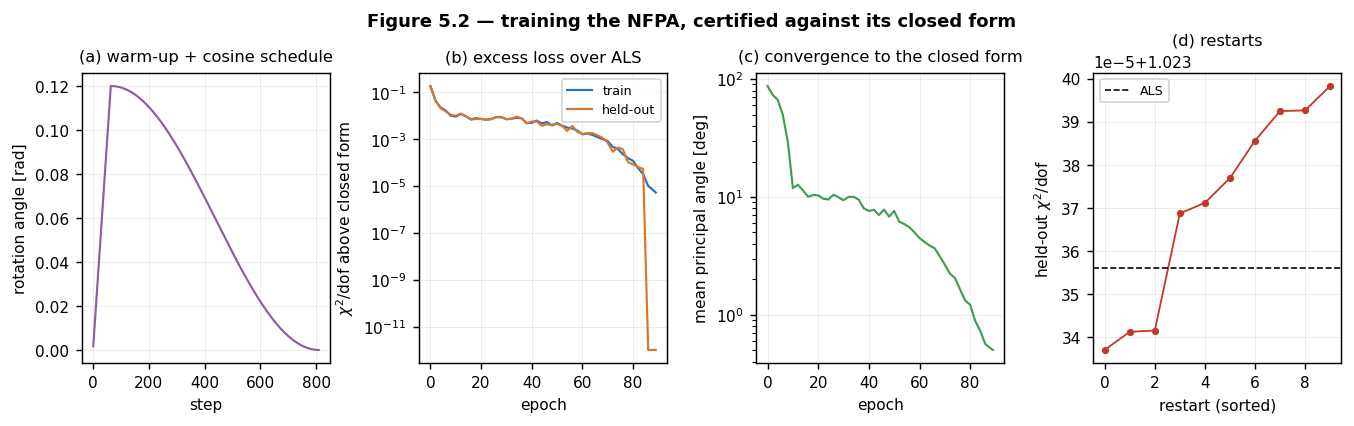

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(12.5, 2.9))
fig.subplots_adjust(wspace=0.36)
axes[0].plot(hist.step_lr, color=CB["purple"], lw=1.2)
axes[0].set(xlabel="step", ylabel="rotation angle [rad]",
            title="(a) warm-up + cosine schedule")
axes[1].semilogy(hist.epoch, np.maximum(np.array(hist.train_loss) - als_tr, 1e-12),
                 color=CB["blue"], lw=1.2, label="train")
axes[1].semilogy(hist.epoch, np.maximum(np.array(hist.val_loss) - als_te, 1e-12),
                 color=CB["orange"], lw=1.2, label="held-out")
axes[1].set(xlabel="epoch", ylabel=r"$\chi^2$/dof above closed form",
            title="(b) excess loss over ALS")
axes[1].legend()
axes[2].semilogy(hist.epoch, hist.angle_to_als, color=CB["green"], lw=1.2)
axes[2].set(xlabel="epoch", ylabel="mean principal angle [deg]",
            title="(c) convergence to the closed form")
axes[3].plot(np.sort(hist.restart_final), "o-", ms=3, color=CB["red"], lw=1)
axes[3].axhline(als_te, color="k", ls="--", lw=0.9, label="ALS")
axes[3].set(xlabel="restart (sorted)", ylabel=r"held-out $\chi^2$/dof",
            title="(d) restarts")
axes[3].legend()
fig.suptitle("Figure 5.2 — training the NFPA, certified against its closed form",
             y=1.04, fontsize=10, fontweight="bold")
plt.show()

### 5.5 What the components mean

To first order one event is

$$x \;\simeq\; A\,\underbrace{h(x_v,y_v)}_{\text{channel factor}}
  \;\otimes\;\underbrace{s(t-t_0;\tau)}_{\text{time factor}}$$

a Kronecker product of two low-dimensional families &mdash; exactly what NFPA
is restricted to. Both bases come from the simulator, never from the fit:

* **time**, $[s,\ \partial_t s,\ \partial_\tau s]$ plus the three
  second-order terms, by finite differences on the CPD response itself;
* **channel**, the multipole expansion of the collection pattern
  $h \simeq h_0 + x_v\partial_x h + y_v\partial_y h + (\text{quadrupoles})$,
  fitted on a **high-statistics calibration grid** over vertex position, so
  it is a measured detector property and not an artefact of the same noisy
  events the model sees.

The channel side carries the interesting wrinkle. Over $r<2.5$ cm the
collection pattern is *curved*: the two dipoles carry only ~60% of its
variation and the quadrupoles another ~25%. That is why $k_c = 6$ rather
than 3 &mdash; a rank-3 channel factor is forced to absorb the quadrupole
residual into its monopole coefficient, which is exactly the coefficient the
amplitude read-out divides by.

First, does the chain factorise at all? The QP arrival spread is sub-sample
(Figure 5.1c), so it should &mdash; and the residual is the part of the event
that genuinely does not.

In [8]:
calib = ds.build_calibration_grid(LIB / "calib_grid.npz", n_qp=CALIB_QP)
B_mult, r2_mult = pb.multipole_basis(calib["share"], calib["meta"][:, 0],
                                     calib["meta"][:, 1], 6)
B_time = ds.downsample(pb.time_tangent(FS, D_RAW, TAU_RISE, TAU_NOM, TRIG,
                                       order=2).T).T
print(f"calibration grid: {calib['share'].shape[0]} points, "
      f"{np.median(calib['meta'][:,3]):.0f} detected QP each")
print("cumulative R^2 of the channel multipole expansion:")
for lab, r in zip(pb.MULTIPOLE_LABELS, r2_mult):
    print(f"   + {lab:<18} {r:.4f}")

sur = ds.downsample(pb.rank1_surrogate(share_te, ndet_te, t0_te, tau_te, QP_AMP,
                                       ds.QP_FRACTION, FS, D_RAW, TAU_RISE, TRIG))
fe = pb.factorisation_error(clean_te, sur)
print(f"\nrank-1 Kronecker surrogate vs the rendered chain: "
      f"median {fe['median']*100:.2f} %, p90 {fe['p90']*100:.2f} %")
print(f"  (electronic noise is {100/np.median(snr):.2f} % of the signal, so the "
      f"non-factorising part is sub-dominant)")

Bt_w = pb.whiten_columns(B_time, W.time_weights, D_T)
Bc_w = W.channel_whitener @ B_mult
_Bn = Bc_w / np.linalg.norm(Bc_w, axis=0)
print(f"\nchannel-basis condition number after whitening: "
      f"{np.linalg.cond(_Bn):.2f}   (monopole/radial-quadrupole overlap "
      f"{_Bn[:,0] @ _Bn[:,5]:+.2f})")

calibration grid: 52 points, 4288 detected QP each
cumulative R^2 of the channel multipole expansion:
   + $h_0$              -0.0000
   + $\partial_x h$     0.3029
   + $\partial_y h$     0.6054
   + $q_{xy}$           0.6562
   + $q_{x^2-y^2}$      0.7777
   + $q_{r^2}$          0.8474

rank-1 Kronecker surrogate vs the rendered chain: median 0.34 %, p90 0.45 %
  (electronic noise is 2.29 % of the signal, so the non-factorising part is sub-dominant)

channel-basis condition number after whitening: 2.04   (monopole/radial-quadrupole overlap -0.61)


#### 5.5.1 The ladder: which physical direction does each rank buy?

A fitted factor is only defined up to a rotation inside its own span, so
asking "is $u_{c,2}$ the $x$ dipole" is the wrong question. The
rotation-invariant one is how much of each physical direction the rank-$k$
subspace contains, $\|UU^{\mathsf T}b_j\|/\|b_j\|$ &mdash; and that gives a
ladder, each extra rank picking up the next physical direction in the order
the physics puts them.

principal angles  U_c vs the 6 multipoles : [ 1.91  5.43 11.15 11.51 17.6  38.65] deg
principal angles  U_t vs [s, dts, dtau s]   : [ 5.14 12.3  24.92] deg
basis energy outside the fitted subspace    : channel 24.3 %, time 27.7 %
mixing-matrix condition numbers  kappa(A_c) = 2.56, kappa(A_t) = 1.16


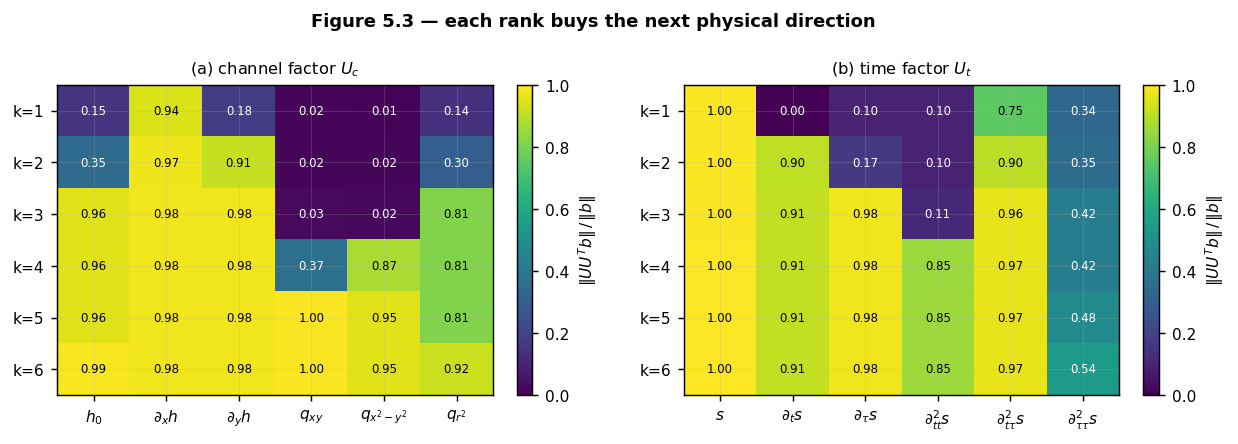

In [9]:
lad_c = np.array([nf.captured_fraction(
    nf.fit_nfpa_als(Z_tr, kk, k_t, n_iter=20, n_restarts=3, seed=0)[0], Bc_w)
    for kk in range(1, 7)])
lad_t = np.array([nf.captured_fraction(
    nf.fit_nfpa_als(Z_tr, k_c, kk, n_iter=20, n_restarts=3, seed=0)[1], Bt_w)
    for kk in range(1, 7)])

gauge = nf.gauge_fix(U_c, U_t, Bc_w[:, :k_c], Bt_w[:, :k_t])
print(f"principal angles  U_c vs the {k_c} multipoles : {np.round(gauge.angles_c,2)} deg")
print(f"principal angles  U_t vs [s, dts, dtau s]   : {np.round(gauge.angles_t,2)} deg")
print(f"basis energy outside the fitted subspace    : "
      f"channel {gauge.resid_c*100:.1f} %, time {gauge.resid_t*100:.1f} %")
print(f"mixing-matrix condition numbers  kappa(A_c) = {gauge.cond_c:.2f}, "
      f"kappa(A_t) = {gauge.cond_t:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.1))
fig.subplots_adjust(wspace=0.30)
for ax, lad, labs, ttl in [
        (axes[0], lad_c, pb.MULTIPOLE_LABELS, r"(a) channel factor $U_c$"),
        (axes[1], lad_t, pb.TIME_LABELS, r"(b) time factor $U_t$")]:
    im = ax.imshow(lad, cmap="viridis", vmin=0, vmax=1, aspect="auto")
    ax.set(xticks=range(len(labs)), xticklabels=labs, yticks=range(6),
           yticklabels=[f"k={i+1}" for i in range(6)], title=ttl)
    for i in range(lad.shape[0]):
        for j in range(lad.shape[1]):
            ax.text(j, i, f"{lad[i,j]:.2f}", ha="center", va="center",
                    fontsize=6.5, color="w" if lad[i, j] < 0.6 else "k")
    fig.colorbar(im, ax=ax, fraction=0.046, label=r"$\|UU^{T}b\|\,/\,\|b\|$")
fig.suptitle("Figure 5.3 — each rank buys the next physical direction",
             y=1.06, fontsize=10, fontweight="bold")
plt.show()

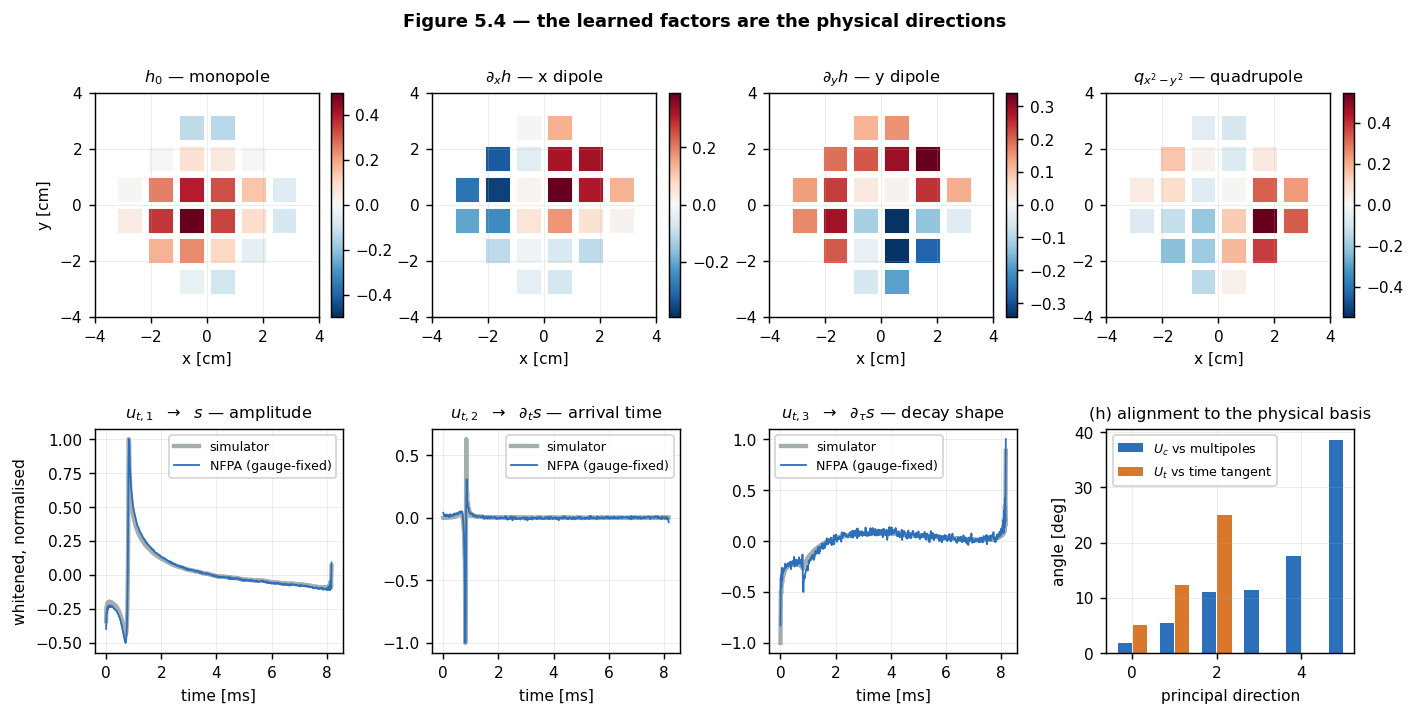

In [10]:
fig = plt.figure(figsize=(12.5, 5.6))
gs = fig.add_gridspec(2, 4, hspace=0.5, wspace=0.36)
Uc_phys = U_c @ np.linalg.pinv(gauge.A_c)
Bc_n = Bc_w[:, :k_c] / np.linalg.norm(Bc_w[:, :k_c], axis=0, keepdims=True)
show_c = [(0, r"$h_0$ — monopole"), (1, r"$\partial_x h$ — x dipole"),
          (2, r"$\partial_y h$ — y dipole"), (4, r"$q_{x^2-y^2}$ — quadrupole")]
for col, (j, ttl) in enumerate(show_c):
    ax = fig.add_subplot(gs[0, col])
    v = Uc_phys[:, j] / np.linalg.norm(Uc_phys[:, j])
    v = v * np.sign(v @ Bc_n[:, j])
    m = np.abs(v).max()
    s = ax.scatter(SENSOR_XY[:, 0], SENSOR_XY[:, 1], c=v, s=190, marker="s",
                   cmap="RdBu_r", vmin=-m, vmax=m, edgecolor="w", linewidth=0.5)
    fig.colorbar(s, ax=ax, fraction=0.046)
    ax.set(title=ttl, aspect="equal", xlim=(-4, 4), ylim=(-4, 4),
           xlabel="x [cm]", ylabel="y [cm]" if col == 0 else "")

Ut_phys = U_t @ np.linalg.pinv(gauge.A_t)
Bt_n = Bt_w[:, :k_t] / np.linalg.norm(Bt_w[:, :k_t], axis=0, keepdims=True)
lab_t = [r"$s$ — amplitude", r"$\partial_t s$ — arrival time",
         r"$\partial_\tau s$ — decay shape"]
for j in range(3):
    ax = fig.add_subplot(gs[1, j])
    a = Ut_phys[:, j] / np.abs(Ut_phys[:, j]).max()
    b = Bt_n[:, j] / np.abs(Bt_n[:, j]).max()
    a = a * np.sign(a @ b)
    ax.plot(t_ms, b, lw=2.4, color=CB["grey"], alpha=0.7, label="simulator")
    ax.plot(t_ms, a, lw=1.0, color=CB["blue"], label="NFPA (gauge-fixed)")
    ax.set(xlabel="time [ms]", title=f"$u_{{t,{j+1}}}$  $\\to$  {lab_t[j]}",
           ylabel="whitened, normalised" if j == 0 else "")
    ax.legend()

ax = fig.add_subplot(gs[1, 3])
ax.bar(np.arange(k_c) - 0.18, gauge.angles_c, width=0.34, color=CB["blue"],
       label=r"$U_c$ vs multipoles")
ax.bar(np.arange(k_t) + 0.18, gauge.angles_t, width=0.34, color=CB["orange"],
       label=r"$U_t$ vs time tangent")
ax.set(xlabel="principal direction", ylabel="angle [deg]",
       title="(h) alignment to the physical basis")
ax.legend()
fig.suptitle("Figure 5.4 — the learned factors are the physical directions",
             y=0.99, fontsize=10, fontweight="bold")
plt.show()

#### 5.5.2 Reading physical parameters off the code

A single point-like deposit makes the code matrix **rank one**,
$\Gamma = A\,(U_c^{\mathsf T}\tilde h)(U_t^{\mathsf T}\tilde s)^{\mathsf T}$,
and that is worth exploiting rather than ignoring. Take the leading singular
triple and rotate each singular vector into the physical basis with the gauge
matrices, $c = A_c^{-1}u_1$ and $r = A_t^{-1}v_1$. The singular value carries
the scale and the singular vectors carry the directions, so

$$\hat A = \sigma_1,\qquad
  \hat x_v = c_1,\quad \hat y_v = c_2,\qquad
  \hat t_0 = r_1,\quad \widehat{\delta\tau} = r_2$$

each up to one calibration constant, none of them fitted per event. Note
there is no division by $c_0$: the SVD has already taken the amplitude out,
and the monopole coefficient is *not* a stable normaliser here &mdash;
whitening suppresses the array's common mode by the ratio of $\Sigma_c$'s
top eigenvalue to the rest, so $c_0$ carries 22% scatter and dividing by it
injects noise instead of removing it.

$\sigma_2/\sigma_1$ comes free and is worth keeping: it is near zero exactly
when the one-deposit assumption holds, so it is a pile-up / multi-site flag.

In [11]:
def read_code(Z, U_c, U_t, gauge):
    """Rank-1 truncate the code and rotate it into the physical basis."""
    Gam = nf.encode(Z, U_c, U_t)
    U1, S1, V1t = np.linalg.svd(Gam)
    u1, v1, s1 = U1[:, :, 0], V1t[:, 0, :], S1[:, 0]
    c = (np.linalg.pinv(gauge.A_c) @ u1.T).T
    r = (np.linalg.pinv(gauge.A_t) @ v1.T).T
    sgn = np.sign(c[:, 0])
    c, r = c * sgn[:, None], r * sgn[:, None]
    return dict(sigma1=s1, rank1_defect=S1[:, 1] / S1[:, 0], c=c, r=r,
                A=s1, x=c[:, 1], y=c[:, 2], t0=r[:, 1], dtau=r[:, 2],
                code=Gam)


rd = read_code(Z_te, U_c, U_t, gauge)
readout = {"A [ADC]": (A_te, rd["A"]),
           "x_v [cm]": (truth_te["x"], rd["x"]),
           "y_v [cm]": (truth_te["y"], rd["y"]),
           "t_0 [us]": (truth_te["t0"] * 1e-3, rd["t0"]),
           "d_tau [ms]": ((truth_te["tau"] - TAU_NOM) * 1e-6, rd["dtau"])}
print(f"median sigma2/sigma1 = {np.median(rd['rank1_defect']):.4f}   "
      "(0 = one point-like deposit)")
print(f"monopole coefficient scatter std(c0)/mean(c0) = "
      f"{np.std(rd['c'][:,0])/np.mean(rd['c'][:,0]):.3f}   "
      f"(Sigma_c eigenvalue ratio {np.linalg.eigvalsh(W.sigma_c)[-1]/np.median(np.linalg.eigvalsh(W.sigma_c)):.0f})\n")
res_tab = {}
print(f"{'physical quantity':<16} {'R^2':>8} {'resid RMS':>12}")
for nm, (tru, est) in readout.items():
    rr, a, b = pb.linear_r2(tru, est)
    res_tab[nm] = rr
    print(f"{nm:<16} {rr:8.4f} {np.std((est-b)/a - tru):12.4g}")

of_kernel = np.outer(Bc_w[:, 0], Bt_w[:, 0])
A_of = np.einsum("nct,ct->n", Z_te, of_kernel) / np.sum(of_kernel ** 2)
r2_of = pb.linear_r2(A_te, A_of)[0]
print(f"\namplitude:  NFPA R^2 {res_tab['A [ADC]']:.4f}  |  "
      f"fixed-template optimal filter R^2 {r2_of:.4f}")
print("  the OF uses one channel pattern for every event; the collected")
print("  fraction depends on where the deposit was, and that is what the")
print("  code supplies.")

median sigma2/sigma1 = 0.0652   (0 = one point-like deposit)
monopole coefficient scatter std(c0)/mean(c0) = 0.221   (Sigma_c eigenvalue ratio 14)

physical quantity      R^2    resid RMS
A [ADC]            0.8544        84.59
x_v [cm]           0.9519       0.2849
y_v [cm]           0.9567       0.2626
t_0 [us]           0.9629        2.759
d_tau [ms]         0.9050       0.2199

amplitude:  NFPA R^2 0.8544  |  fixed-template optimal filter R^2 0.6754
  the OF uses one channel pattern for every event; the collected
  fraction depends on where the deposit was, and that is what the
  code supplies.


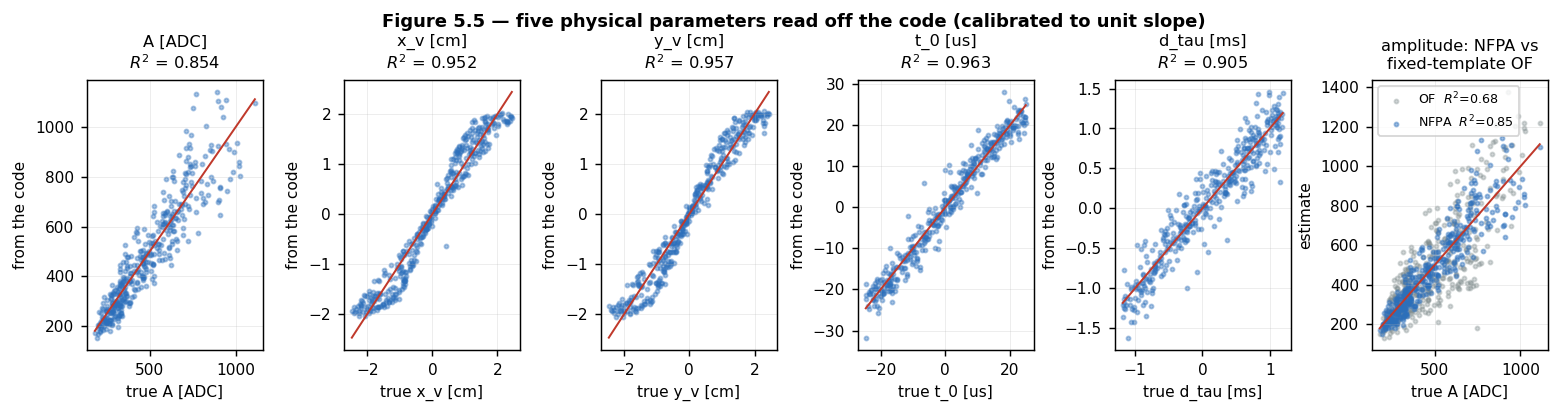

In [12]:
fig, axes = plt.subplots(1, 6, figsize=(14.5, 2.7))
fig.subplots_adjust(wspace=0.46)
for ax, (nm, (tru, est)) in zip(axes, readout.items()):
    rr, a, b = pb.linear_r2(tru, est)
    ax.scatter(tru, (est - b) / a, s=5, alpha=0.4, color=CB["blue"])
    lo, hi = np.min(tru), np.max(tru)
    ax.plot([lo, hi], [lo, hi], color=CB["red"], lw=1.1)
    ax.set(xlabel=f"true {nm}", ylabel="from the code",
           title=f"{nm}\n$R^2$ = {rr:.3f}")
ax = axes[5]
a, b = np.polyfit(A_te, rd["A"], 1)
ao, bo = np.polyfit(A_te, A_of, 1)
ax.scatter(A_te, (A_of - bo) / ao, s=5, alpha=0.35, color=CB["grey"],
           label=f"OF  $R^2$={r2_of:.2f}")
ax.scatter(A_te, (rd["A"] - b) / a, s=5, alpha=0.45, color=CB["blue"],
           label=f"NFPA  $R^2$={res_tab['A [ADC]']:.2f}")
ax.plot([A_te.min(), A_te.max()], [A_te.min(), A_te.max()], color=CB["red"], lw=1.1)
ax.set(xlabel="true A [ADC]", ylabel="estimate",
       title="amplitude: NFPA vs\nfixed-template OF")
ax.legend()
fig.suptitle("Figure 5.5 — five physical parameters read off the code "
             "(calibrated to unit slope)", y=1.07, fontsize=10, fontweight="bold")
plt.show()

### 5.6 Diagnostics: move one factor, watch one read-out

The payoff of a structured latent is that "which factor moved" becomes an
index rather than a projector fitted after the fact. Each one-factor cell
freezes everything but a single physical quantity. The model is **frozen** on
the reference cell &mdash; nothing is refitted &mdash; and the prediction is
that the spread of the read-outs concentrates in the one that factor owns.

energy_only    largest spread in A     (predicted A    ) yes
x_only         largest spread in x     (predicted x    ) yes
y_only         largest spread in y     (predicted y    ) yes
t0_only        largest spread in t0    (predicted t0   ) yes
tau_only       largest spread in dtau  (predicted dtau ) yes

5/5 cells land on the predicted read-out


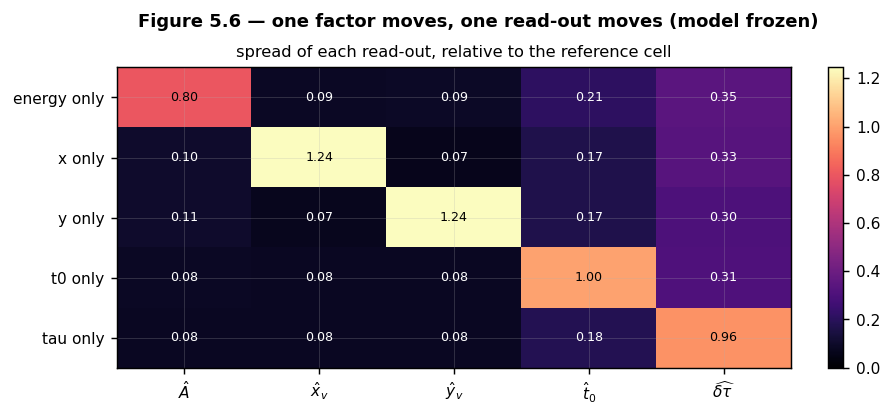

In [13]:
KEYS = ["A", "x", "y", "t0", "dtau"]
EXPECT = {"energy_only": "A", "x_only": "x", "y_only": "y",
          "t0_only": "t0", "tau_only": "dtau"}
ref_spread = np.array([np.std(rd[k]) for k in KEYS])

rows_cell, hits = [], 0
for nm, lib in CELL_LIBS.items():
    t0c, tauc = ds.response_params(N_CELL, seed=200 + len(nm), cell=nm)
    Zc = W.whiten(ds.downsample(ds.add_noise(
        ds.render_traces(lib, t0=t0c, tau=tauc), seed=30_000 + len(nm))))
    rc = read_code(Zc, U_c, U_t, gauge)
    sp = np.array([np.std(rc[k]) for k in KEYS]) / ref_spread
    rows_cell.append((nm, sp))
    got = KEYS[int(np.argmax(sp))]
    hits += got == EXPECT[nm]
    print(f"{nm:<14} largest spread in {got:<5} (predicted {EXPECT[nm]:<5}) "
          f"{'yes' if got == EXPECT[nm] else 'NO'}")
print(f"\n{hits}/{len(rows_cell)} cells land on the predicted read-out")

fig, ax = plt.subplots(figsize=(7.4, 3.0))
M = np.array([r[1] for r in rows_cell])
im = ax.imshow(M, cmap="magma", vmin=0, vmax=max(1.05, M.max()), aspect="auto")
ax.set(xticks=range(len(KEYS)),
       xticklabels=[r"$\hat A$", r"$\hat x_v$", r"$\hat y_v$",
                    r"$\hat t_0$", r"$\widehat{\delta\tau}$"],
       yticks=range(len(rows_cell)),
       yticklabels=[r[0].replace("_", " ") for r in rows_cell],
       title="spread of each read-out, relative to the reference cell")
for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        ax.text(j, i, f"{M[i,j]:.2f}", ha="center", va="center", fontsize=7,
                color="w" if M[i, j] < 0.6 * M.max() else "k")
fig.colorbar(im, ax=ax, fraction=0.046)
fig.suptitle("Figure 5.6 — one factor moves, one read-out moves (model frozen)",
             y=1.02, fontsize=10, fontweight="bold")
plt.show()

### 5.7 Ablations: the metric, and giving up the restriction

Two comparators, both through the identical code path:

* **Iso-MPCA** &mdash; the same architecture with $\Sigma = I$. The metric
  ablation: if the alignment above came from the Kronecker restriction alone,
  Iso-MPCA would show it too.
* **CW-PCA rank $k_ck_t$** &mdash; the unrestricted class in the same metric,
  with two orders of magnitude more free parameters. It must reconstruct at
  least as well; the question is whether its axes mean anything.

The result is sharper than a blanket win. The two models agree to three
decimal places on the **channel** read-outs, and they should: after
$\Sigma_c^{-1/2}$ the channel noise is nearly white either way, so the metric
has little left to do there. On the **time** side, where the noise is pink
and the signal sits in the same decade, the metric is the whole story
&mdash; Iso-MPCA loses the arrival time almost completely and half of the
decay shape, and its time-side gauge matrix is an order of magnitude worse
conditioned. The metric reversal is textbook: NFPA wins in $\chi^2$ and
loses in raw MSE, because those are two different geometries and only one of
them is the detector's.

In [14]:
Uc_iso, Ut_iso = nf.fit_nfpa_als(X_tr, k_c, k_t, n_iter=30, n_restarts=6, seed=0)
Uc_iso_w = np.linalg.qr(W.channel_whitener @ Uc_iso)[0]
Ut_iso_w = np.linalg.qr(pb.whiten_columns(Ut_iso, W.time_weights, D_T))[0]
U_cw = nf.unrestricted_cwpca(Z_tr, k_c * k_t)
B_kron = nf.kron_basis(Bc_w[:, :k_c], Bt_w[:, :k_t])
g_iso = nf.gauge_fix(Uc_iso_w, Ut_iso_w, Bc_w[:, :k_c], Bt_w[:, :k_t])

Zf_te = Z_te.reshape(len(Z_te), -1)
rows = [
    ("NFPA", p_nfpa, nf.nfpa_loss(Z_te, U_c, U_t),
     float(np.mean((X_te - W.unwhiten(nf.decode(nf.encode(Z_te, U_c, U_t), U_c, U_t))) ** 2)),
     nf.principal_angles_deg(nf.kron_basis(U_c, U_t), B_kron)),
    ("Iso-MPCA", p_nfpa, nf.nfpa_loss(Z_te, Uc_iso_w, Ut_iso_w),
     float(np.mean((X_te - nf.decode(nf.encode(X_te, Uc_iso, Ut_iso), Uc_iso, Ut_iso)) ** 2)),
     nf.principal_angles_deg(nf.kron_basis(Uc_iso_w, Ut_iso_w), B_kron)),
    (f"CW-PCA r{k_c*k_t}", p_full,
     float(np.mean((Zf_te - (Zf_te @ U_cw) @ U_cw.T) ** 2)),
     float(np.mean((X_te - W.unwhiten(((Zf_te @ U_cw) @ U_cw.T).reshape(Z_te.shape))) ** 2)),
     nf.principal_angles_deg(U_cw, B_kron)),
]
print(f"{'model':<11} {'params':>9} {'chi2/dof':>10} {'raw MSE':>10} "
      f"{'mean ang':>9} {'max ang':>9}")
for nm, par, chi2, mse, ang in rows:
    print(f"{nm:<11} {par:>9,} {chi2:>10.5f} {mse:>10.2f} "
          f"{np.mean(ang):>9.2f} {np.max(ang):>9.2f}")

rd_iso = read_code(Z_te, Uc_iso_w, Ut_iso_w, g_iso)
iso_read = {nm: pb.linear_r2(tru, rd_iso[k])[0]
            for (nm, (tru, _)), k in zip(readout.items(), KEYS)}
print(f"\n{'read-out':<14} {'NFPA':>8} {'Iso-MPCA':>10}")
for kk in res_tab:
    print(f"{kk:<14} {res_tab[kk]:>8.4f} {iso_read[kk]:>10.4f}")
print(f"\nkappa(A_c), kappa(A_t):  NFPA {gauge.cond_c:.2f}, {gauge.cond_t:.2f}  |  "
      f"Iso-MPCA {g_iso.cond_c:.2f}, {g_iso.cond_t:.2f}")

model          params   chi2/dof    raw MSE  mean ang   max ang
NFPA            1,635    1.02334     120.34     21.99     44.91
Iso-MPCA        1,635    1.02833      21.00     41.83     85.63
CW-PCA r18    220,860    1.01748     118.66     56.57     89.90

read-out           NFPA   Iso-MPCA
A [ADC]          0.8544     0.8541
x_v [cm]         0.9519     0.9530
y_v [cm]         0.9567     0.9561
t_0 [us]         0.9629     0.2024
d_tau [ms]       0.9050     0.6022

kappa(A_c), kappa(A_t):  NFPA 2.56, 1.16  |  Iso-MPCA 2.43, 11.21


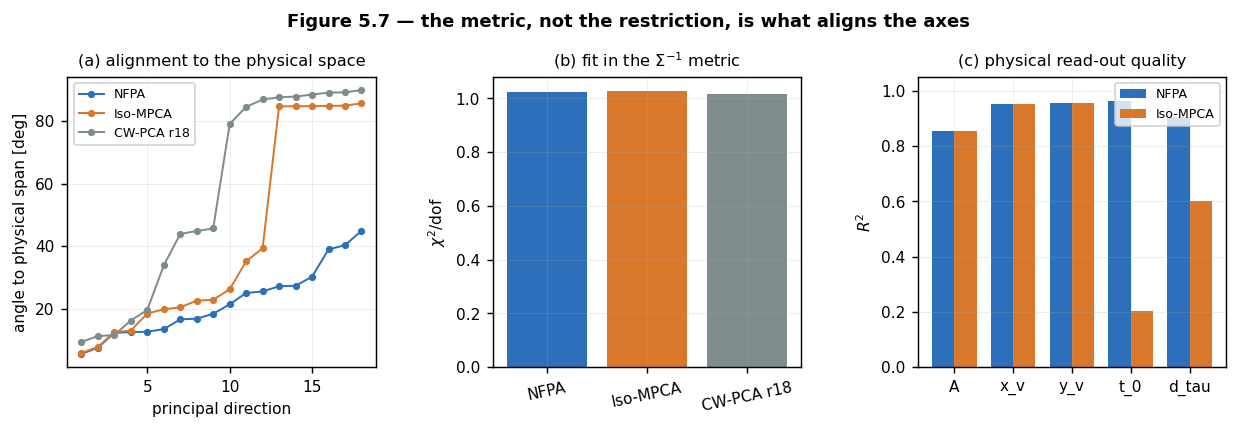

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(11.5, 2.9))
fig.subplots_adjust(wspace=0.38)
cols = [CB["blue"], CB["orange"], CB["grey"]]
for i, (nm, par, chi2, mse, ang) in enumerate(rows):
    axes[0].plot(np.arange(1, len(ang) + 1), ang, "o-", ms=3, lw=1.1,
                 label=nm, color=cols[i])
axes[0].set(xlabel="principal direction", ylabel="angle to physical span [deg]",
            title="(a) alignment to the physical space")
axes[0].legend()
axes[1].bar([r[0] for r in rows], [r[2] for r in rows], color=cols)
axes[1].set(ylabel=r"$\chi^2$/dof", title=r"(b) fit in the $\Sigma^{-1}$ metric")
axes[1].tick_params(axis="x", labelrotation=12)
ks = list(res_tab)
axes[2].bar(np.arange(len(ks)) - 0.19, [res_tab[k] for k in ks], width=0.38,
            color=CB["blue"], label="NFPA")
axes[2].bar(np.arange(len(ks)) + 0.19, [iso_read[k] for k in ks], width=0.38,
            color=CB["orange"], label="Iso-MPCA")
axes[2].set(xticks=range(len(ks)), xticklabels=[k.split()[0] for k in ks],
            ylabel=r"$R^2$", ylim=(0, 1.05), title="(c) physical read-out quality")
axes[2].legend()
fig.suptitle("Figure 5.7 — the metric, not the restriction, is what aligns the axes",
             y=1.05, fontsize=10, fontweight="bold")
plt.show()

### 5.8 Where the linear picture stops

A time shift is not a low-rank operation. $\partial_t s$ is only the first
term of $s(t-t_0)$, and the expansion holds while
$\sigma_{t_0}f_{\rm sig}\ll1$, with the bandwidth set by the rise time.
Because the event library stores arrival times rather than traces, the whole
sweep is a re-render: the physics is held fixed and only the trigger jitter
changes.

What comes out is a **window**, not a ceiling. Too little jitter and the
$\partial_t s$ direction carries less variance than the
Marchenko&ndash;Pastur edge, so the fit never finds it and the read-out is
noise; too much and the second-order term $\partial^2_{tt}s$ claims a slot of
its own, the tangent stops spanning the shifted-pulse manifold, and the
read-out degrades again. The usable band here is roughly
$0.02 \lesssim \sigma_{t_0}f_{\rm sig} \lesssim 0.1$.

sigma_t    3.6 us | sigma_t*f_sig  0.011 | t0 read-out R^2 0.2740 | max U_t angle  62.96 deg | 2nd-order captured 0.203
sigma_t    7.2 us | sigma_t*f_sig  0.023 | t0 read-out R^2 0.9212 | max U_t angle  11.97 deg | 2nd-order captured 0.163
sigma_t   14.4 us | sigma_t*f_sig  0.046 | t0 read-out R^2 0.9647 | max U_t angle  24.77 deg | 2nd-order captured 0.101
sigma_t   28.9 us | sigma_t*f_sig  0.092 | t0 read-out R^2 0.7305 | max U_t angle  83.88 deg | 2nd-order captured 0.426
sigma_t   57.8 us | sigma_t*f_sig  0.184 | t0 read-out R^2 0.5350 | max U_t angle  84.46 deg | 2nd-order captured 0.195
sigma_t  115.6 us | sigma_t*f_sig  0.368 | t0 read-out R^2 0.3661 | max U_t angle  84.45 deg | 2nd-order captured 0.083


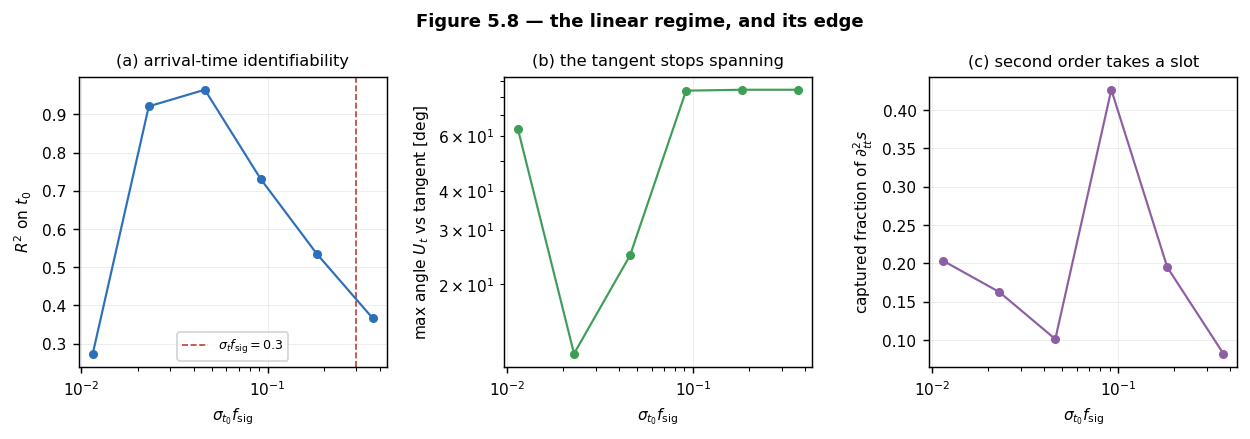

In [16]:
sweep = []
for scale in (0.25, 0.5, 1.0, 2.0, 4.0, 8.0):
    rs = np.random.default_rng(7)
    t0s = rs.uniform(-ds.T0_JITTER * scale, ds.T0_JITTER * scale, N_TRAIN)
    Zs = W.whiten(ds.downsample(ds.add_noise(
        ds.render_traces(train_lib, t0=t0s, tau=tau_tr),
        seed=int(3000 + 10 * scale))))
    uc, ut = nf.fit_nfpa_als(Zs, k_c, k_t, n_iter=25, n_restarts=3, seed=0)
    gg = nf.gauge_fix(uc, ut, Bc_w[:, :k_c], Bt_w[:, :k_t])
    rr = pb.linear_r2(t0s, read_code(Zs, uc, ut, gg)["t0"])[0]
    nl = np.std(t0s) * 1e-9 * F_SIG
    cap2 = nf.captured_fraction(ut, Bt_w[:, 3:4])[0]
    sweep.append((nl, rr, float(np.max(gg.angles_t)), cap2))
    print(f"sigma_t {np.std(t0s)*1e-3:6.1f} us | sigma_t*f_sig {nl:6.3f} | "
          f"t0 read-out R^2 {rr:.4f} | max U_t angle {np.max(gg.angles_t):6.2f} deg | "
          f"2nd-order captured {cap2:.3f}")
sweep = np.array(sweep)

fig, axes = plt.subplots(1, 3, figsize=(11.5, 2.9))
fig.subplots_adjust(wspace=0.38)
axes[0].semilogx(sweep[:, 0], sweep[:, 1], "o-", color=CB["blue"], lw=1.2, ms=4)
axes[0].axvline(0.3, color=CB["red"], ls="--", lw=0.9,
                label=r"$\sigma_t f_{\rm sig} = 0.3$")
axes[0].set(xlabel=r"$\sigma_{t_0} f_{\rm sig}$", ylabel=r"$R^2$ on $t_0$",
            title="(a) arrival-time identifiability")
axes[0].legend()
axes[1].loglog(sweep[:, 0], sweep[:, 2], "o-", color=CB["green"], lw=1.2, ms=4)
axes[1].set(xlabel=r"$\sigma_{t_0} f_{\rm sig}$",
            ylabel=r"max angle $U_t$ vs tangent [deg]",
            title="(b) the tangent stops spanning")
axes[2].semilogx(sweep[:, 0], sweep[:, 3], "o-", color=CB["purple"], lw=1.2, ms=4)
axes[2].set(xlabel=r"$\sigma_{t_0} f_{\rm sig}$",
            ylabel=r"captured fraction of $\partial^2_{tt}s$",
            title="(c) second order takes a slot")
fig.suptitle("Figure 5.8 — the linear regime, and its edge", y=1.05,
             fontsize=10, fontweight="bold")
plt.show()

### 5.9 Recap

In order:

1. The HeST &rarr; `QPSimulator` chain factorises: one event is an amplitude
   times a channel pattern times a pulse shape, to well inside the noise. The
   QP arrival spread is sub-microsecond and therefore invisible at 250 kHz
   &mdash; a physical statement about HeRALD, not a modelling convenience.
2. A gradient-trained NFPA with a warm-up/cosine schedule reaches the
   closed-form Tucker-2 optimum, so the parameterisation optimises what it
   claims to.
3. Each rank buys the next physical direction, in the order the physics puts
   them: monopole, the two position dipoles, then quadrupoles on the channel
   side; pulse, arrival time, decay shape on the time side. How many ranks
   the data can support is set by the Marchenko&ndash;Pastur edge, which is
   why the record is decimated to the signal bandwidth first &mdash; and
   which also gives §5.8 its lower edge: a factor too weak to clear the bulk
   is not a factor the model can find, however physical it is.
4. The code matrix is rank one per deposit. Its singular triple, rotated into
   the physical basis, gives amplitude, vertex, arrival time and decay shape
   as calibrated read-outs &mdash; and beats a fixed-template optimal filter
   on amplitude, because the collected fraction depends on where the deposit
   was and the code knows where it was.
5. Moving one factor moves one read-out, with the model frozen &mdash; the
   lookup that makes this a diagnostic rather than a description.
6. The metric does the work exactly where the noise is coloured: Iso-MPCA,
   same architecture and same parameter count, matches NFPA on the channel
   read-outs and loses the arrival time and half the decay shape on the time
   side, with a gauge matrix an order of magnitude worse conditioned.

**Limitations.** The HeRALD_v1 constants are HeST defaults, not values read
from arXiv:2307.11877. ER/NR is degenerate with energy in a
quasiparticle-only readout, so event type is not one of the factors here.
The Kronecker restriction forbids a position-dependent pulse shape, which is
a real effect once the arrival spread is resolved; at 250 kHz it is not.
The collection pattern is curved over $r<2.5$ cm, so the multipole expansion
is truncated rather than complete &mdash; Figure 5.3a quantifies what is left
on the table. And thinning at `qp_fraction = 0.15` inflates QP shot noise by
$1/\sqrt{0.15}\approx 2.6$ relative to a full-statistics run.